# EDA — Délinquance enregistrée

**Projet :** Compagnon Immobilier · **Auteur :** Cécile NAUDET · **Date :** 17/10/2026
**Fiche d'audit associée :** `CN_audit_delinquance.ipynb`

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from pathlib import Path
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

data = Path("/home/naude/formation/projet_compagnon/data")
delinq = pd.read_parquet(data / "dataset_delinquance_communale.parquet")

def eta2_kruskal(groupes):
    """Kruskal-Wallis + taille d'effet eta² (part de la variabilité des rangs expliquée par les groupes)."""
    H, p = stats.kruskal(*groupes)
    k, n = len(groupes), sum(len(g) for g in groupes)
    return H, p, (H - k + 1) / (n - k)

def r_mannwhitney(a, b):
    """Mann-Whitney + taille d'effet r rang-bisérial (de -1 à 1).
    r > 0 : les valeurs de a ont tendance à être plus élevées que celles de b.
    (1 + r) / 2 = probabilité qu'une valeur tirée dans a dépasse une valeur tirée dans b."""
    U, p = stats.mannwhitneyu(a, b)
    return U, p, 2 * U / (len(a) * len(b)) - 1


### Construction provisoire de la table cible au bassin de vie

Cette table sera déplacée dans le notebook de preprocessing (partie 4) une fois la maille des grandes villes décidée. Même calcul que la table cible communale, mais chaque vente est d'abord rattachée à son bassin de vie : le prix médian est recalculé à partir des ventes, car une médiane ne s'obtient pas en combinant les médianes des communes.

In [2]:
# 1. Table de correspondance : une ligne par code commune d'origine (règles du test de rattachement)
liaison = pd.read_csv(data / "dataset_cible" / "bv_liaison_2022.csv", dtype=str, index_col=0)
dup = liaison["CODGEO_INI"].duplicated(keep=False)
identite = liaison["CODGEO_INI"] == liaison["CODGEO_2026"]
cas_52427 = (liaison["CODGEO_INI"] == "52427") & (liaison["CODGEO_2026"] == "52331")
liaison_ini = liaison.loc[~dup | identite | cas_52427, ["CODGEO_INI", "BV2022"]]

# 2. Ventes : mêmes colonnes et mêmes règles d'exclusion que la table communale
pop = pd.read_parquet(data / "dvf_plus_residentiel",
                      columns=["anneemut", "l_codinsee", "libtypbien", "valeurfonc", "sbati"])
pop["prix_m2"] = pop["valeurfonc"] / pop["sbati"]
pop = pop[pop["valeurfonc"].notna() & (pop["valeurfonc"] > 0) & pop["prix_m2"].between(50, 50000)]
pop["type_bien"] = pop["libtypbien"].map({"UNE MAISON": "maison", "UN APPARTEMENT": "appart"})

# 3. Rattachement de chaque vente à son bassin de vie
pop = pop.merge(liaison_ini, left_on="l_codinsee", right_on="CODGEO_INI",
                how="left", validate="many_to_one")

# 4. Maille : bassin de vie (option A) ou arrondissements séparés pour Paris, Lyon, Marseille (option B)
DECOUPER_GRANDES_VILLES = False
pop["maille"] = pop["BV2022"]
if DECOUPER_GRANDES_VILLES:
    arrondissement = pop["l_codinsee"].str.match(r"^(751|6938|132)")
    pop.loc[arrondissement, "maille"] = pop.loc[arrondissement, "l_codinsee"]

# 5. Une ligne par maille × année, le type de bien en colonnes
cible_bv = (pop.groupby(["maille", "anneemut", "type_bien"])["prix_m2"]
               .agg(n="count", prix_m2_med="median")
               .unstack("type_bien"))
cible_bv.columns = [f"{stat}_{typ}" for stat, typ in cible_bv.columns]
cible_bv = cible_bv.reset_index().rename(columns={"anneemut": "annee"})
for col in ["n_maison", "n_appart"]:
    cible_bv[col] = cible_bv[col].fillna(0).astype(int)

print(cible_bv.shape)
print("Mailles :", cible_bv["maille"].nunique())
print("Total des ventes :", cible_bv["n_appart"].sum() + cible_bv["n_maison"].sum())   # doit valoir 9 655 421

(19355, 6)
Mailles : 1613
Total des ventes : 9655421


### Construction provisoire de la délinquance au bassin de vie

Taux recalculés par bassin de vie et par année : somme des faits divisée par la somme des habitants (des logements pour les cambriolages). Les communes masquées reçoivent la moyenne départementale des communes masquées (`complement_info_nombre`). Paris, Lyon et Marseille suivent la même option de maille que la table cible.

In [3]:
# 1. Correspondance code 2026 -> bassin de vie
liaison_2026 = liaison[["CODGEO_2026", "BV2022"]].drop_duplicates()

# 2. Paris, Lyon, Marseille : un seul niveau, selon l'option choisie pour la cible
arrondissement = delinq["CODGEO_2026"].str.match(r"^(751|6938|132)")
ville_entiere = delinq["CODGEO_2026"].isin(["75056", "69123", "13055"])
if DECOUPER_GRANDES_VILLES:
    d = delinq[~ville_entiere]    # option B : on garde les arrondissements
else:
    d = delinq[~arrondissement]   # option A : on garde la ville entière

# 3. Rattachement au bassin de vie, et maille identique à celle de la cible
d = d.merge(liaison_2026, on="CODGEO_2026", how="left", validate="many_to_one")
d["maille"] = d["BV2022"]
if DECOUPER_GRANDES_VILLES:
    a = d["CODGEO_2026"].str.match(r"^(751|6938|132)")
    d.loc[a, "maille"] = d.loc[a, "CODGEO_2026"]

# 4. Communes masquées : moyenne départementale ; dénominateur : logements pour les cambriolages
d["nombre_estime"] = d["nombre"].fillna(d["complement_info_nombre"])
d["denominateur"] = np.where(d["indicateur"] == "Cambriolages de logement", d["insee_log"], d["insee_pop"])

# 5. Somme des faits et des habitants par maille × année × indicateur, puis taux
delinq_bv = (d.groupby(["maille", "annee", "indicateur"], observed=True)[["nombre_estime", "denominateur"]]
              .sum().reset_index())
delinq_bv["taux"] = delinq_bv["nombre_estime"] / delinq_bv["denominateur"] * 1000

# 6. Format large : une ligne par maille × année, une colonne par indicateur
delinq_bv["indicateur"] = delinq_bv["indicateur"].astype(str)   # évite les colonnes vides des 3 indicateurs départementaux
taux_bv = delinq_bv.pivot(index=["maille", "annee"], columns="indicateur", values="taux").reset_index()

print(taux_bv.shape)
print("Mailles :", taux_bv["maille"].nunique())

(17070, 17)
Mailles : 1707


# 0. Cadre de l'analyse

**Objectif :** comprendre comment les indicateurs de délinquance se rapprochent ou se distinguent les uns des autres, puis étudier leur lien avec le prix au m², et surtout avec son évolution.

| Élément | Choix |
|---|---|
| Source | Délinquance enregistrée par la police et la gendarmerie (SSMSI), base communale. Voir la fiche d'audit. |
| Maille | Une ligne = un bassin de vie × une année. Paris, Lyon et Marseille en ville entière (option A), en attendant la décision de l'équipe sur les grandes villes. |
| Période | 2016-2024. 2025 est l'année de test : elle est exclue. |
| Cible | Prix médian au m² par bassin de vie et par année, recalculé à partir des ventes DVF+ (construction provisoire ci-dessus). |
| Clé de rapprochement | `maille` + `annee`. |
| Indicateurs | 15 taux pour 1 000 habitants (pour 1 000 logements pour les cambriolages). Les communes masquées sont complétées par la moyenne départementale des communes masquées. |
| Points d'attention | Délinquance enregistrée et non délinquance réelle ; indicateurs sur les stupéfiants liés à l'activité des services ; chiffres d'une année arrêtés en avril de l'année suivante. |



In [4]:
# 2025 est l'année de test : on la retire dès maintenant de toute l'EDA
cible_bv = cible_bv[cible_bv["annee"] <= 2024]
taux_bv = taux_bv[taux_bv["annee"] <= 2024]
print(cible_bv.shape, taux_bv.shape)

(17742, 6) (15363, 17)


In [5]:
import geopandas as gpd

# Contours des bassins de vie : contours des communes, fusionnés par bassin
url = "https://raw.githubusercontent.com/gregoiredavid/france-geojson/master/communes-version-simplifiee.geojson"
communes = gpd.read_file(url)
communes = communes.merge(liaison_ini, left_on="code", right_on="CODGEO_INI", how="left")
carte_bv = communes.dissolve(by="BV2022").reset_index()[["BV2022", "geometry"]]

# Taux lissés d'une période : somme des faits / somme des habitants, au niveau demandé
def taux_periode(df, debut, fin, cles):
    t = df[df["annee"].between(debut, fin)].groupby(cles)[["nombre_estime", "denominateur"]].sum()
    return t["nombre_estime"] / t["denominateur"] * 1000

# B. Relations entre les indicateurs de délinquance

### B1. Redondances entre indicateurs

**Variables :** les 15 taux de délinquance par bassin de vie.

**Pourquoi regarder cela :** plusieurs indicateurs risquent de porter la même information (par exemple, l'usage de stupéfiants et sa partie sanctionnée par amende, ou les trois types de vols liés aux véhicules). Repérer ces redondances permet de garder un seul indicateur par groupe pour la suite.

**Méthode :** matrice des corrélations de Spearman entre les 15 taux, sur tous les bassins de vie et toutes les années 2016-2024. On utilise Spearman plutôt que Pearson parce que les distributions sont asymétriques, avec quelques valeurs extrêmes (fiche d'audit, section 7).



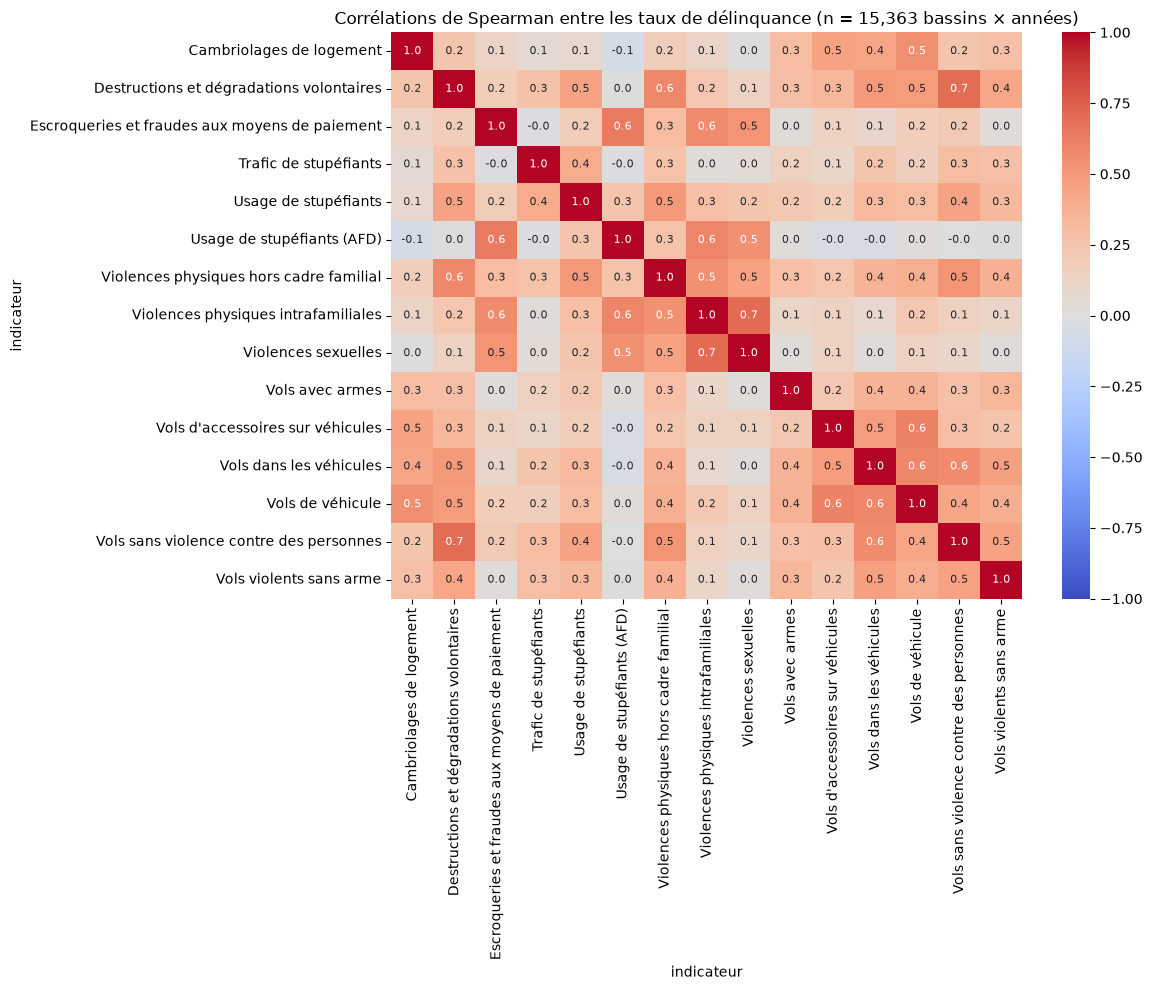

In [6]:
indicateurs = [c for c in taux_bv.columns if c not in ["maille", "annee"]]

corr = taux_bv[indicateurs].corr(method="spearman")

plt.figure(figsize=(12, 10))
sns.heatmap(corr, cmap="coolwarm", vmin=-1, vmax=1, center=0,
            annot=True, fmt=".1f", annot_kws={"size": 8})
plt.title(f"Corrélations de Spearman entre les taux de délinquance (n = {len(taux_bv):,} bassins × années)")
plt.tight_layout()
plt.show()

**Constat :** aucun couple d'indicateurs n'est lié à |rho| ≥ 0,9 : les 15 taux portent des informations assez distinctes. Trois groupes apparaissent avec des liens moyens à forts (rho de 0,4 à 0,7) :
- **délinquance de voie publique** : destructions et dégradations, vols sans violence contre des personnes, vols dans les véhicules, violences physiques hors cadre familial, vols violents sans arme (rho jusqu'à 0,7 entre destructions et vols sans violence) ;
- **vols liés aux véhicules** : vols de véhicule, vols dans les véhicules, vols d'accessoires (rho de 0,5 à 0,6), dont se rapprochent un peu les cambriolages (0,4 à 0,5) ;
- **violences intrafamiliales, violences sexuelles, escroqueries et usage de stupéfiants (AFD)** (rho de 0,5 à 0,7).



**Méthode :** les 15 indicateurs sont regroupés en 8 familles. On n'additionne que des indicateurs de même nature et de même unité de compte. Pour chaque famille, les faits sont additionnés puis rapportés à la population (aux logements pour les cambriolages).

| Famille | Indicateurs | Unité de compte |
|---|---|---|
| Cambriolages | Cambriolages de logement | Infraction (pour 1 000 logements) |
| Vols liés aux véhicules | Vols de véhicule, vols dans les véhicules, vols d'accessoires sur véhicules | Véhicule |
| Vols violents | Vols avec armes, vols violents sans arme | Infraction |
| Vols sans violence | Vols sans violence contre des personnes | Victime entendue |
| Violences | Violences physiques intrafamiliales, violences physiques hors cadre familial, violences sexuelles | Victime |
| Stupéfiants | Trafic de stupéfiants, usage de stupéfiants | Mis en cause |
| Escroqueries | Escroqueries et fraudes aux moyens de paiement | Victime |
| Destructions et dégradations | Destructions et dégradations volontaires | Infraction |

L'usage de stupéfiants (AFD) n'est pas ajouté : il fait déjà partie de l'usage de stupéfiants.


In [7]:
# Correspondance indicateur -> famille (AFD exclu : déjà compris dans l'usage de stupéfiants)
familles = {
    "Cambriolages de logement": "Cambriolages",
    "Vols de véhicule": "Vols liés aux véhicules",
    "Vols dans les véhicules": "Vols liés aux véhicules",
    "Vols d'accessoires sur véhicules": "Vols liés aux véhicules",
    "Vols avec armes": "Vols violents",
    "Vols violents sans arme": "Vols violents",
    "Vols sans violence contre des personnes": "Vols sans violence",
    "Violences physiques intrafamiliales": "Violences",
    "Violences physiques hors cadre familial": "Violences",
    "Violences sexuelles": "Violences",
    "Trafic de stupéfiants": "Stupéfiants",
    "Usage de stupéfiants": "Stupéfiants",
    "Escroqueries et fraudes aux moyens de paiement": "Escroqueries",
    "Destructions et dégradations volontaires": "Destructions et dégradations",
}

fam = delinq_bv[(delinq_bv["annee"] <= 2024) & delinq_bv["indicateur"].isin(familles)].copy()
fam["famille"] = fam["indicateur"].map(familles)

# Faits additionnés dans chaque famille ; population (ou logements) comptée une seule fois
fam = (fam.groupby(["maille", "annee", "famille"])
          .agg(nombre_estime=("nombre_estime", "sum"), denominateur=("denominateur", "first"))
          .reset_index())
fam["taux"] = fam["nombre_estime"] / fam["denominateur"] * 1000

# Format large : une ligne par bassin × année, une colonne par famille
taux_fam = fam.pivot(index=["maille", "annee"], columns="famille", values="taux").reset_index()
liste_familles = ["Cambriolages", "Vols liés aux véhicules", "Vols violents", "Vols sans violence",
                  "Violences", "Stupéfiants", "Escroqueries", "Destructions et dégradations"]

print(taux_fam.shape)

(15363, 10)


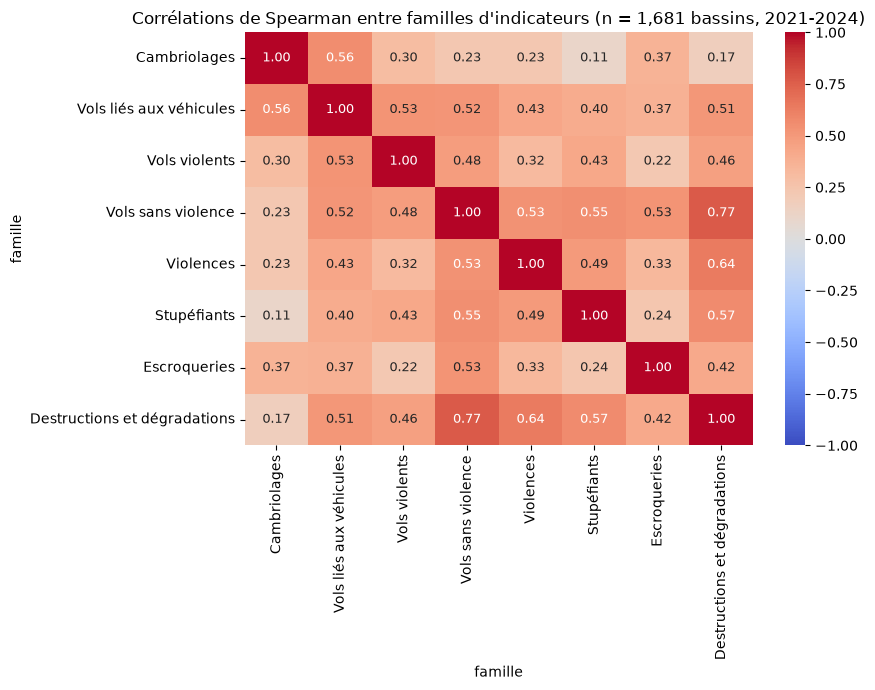

In [8]:
# Une ligne par bassin : taux lissés sur 2021-2024, DOM exclus
l21 = taux_periode(fam, 2021, 2024, ["maille", "famille"]).unstack("famille").reset_index()
l21_metro = l21[l21["maille"].str[:2] != "97"]

corr_fam = l21_metro[liste_familles].corr(method="spearman")

plt.figure(figsize=(9, 7))
sns.heatmap(corr_fam, cmap="coolwarm", vmin=-1, vmax=1, center=0,
            annot=True, fmt=".2f", annot_kws={"size": 9})
plt.title(f"Corrélations de Spearman entre familles d'indicateurs (n = {len(l21_metro):,} bassins, 2021-2024)")
plt.tight_layout()
plt.show()

**Constat :**
- Aucun couple de familles n'est lié à |rho| ≥ 0,9 : le lien le plus fort est 0,77 (vols sans violence et destructions et dégradations). Les huit familles portent des informations distinctes.
- Quatre familles forment un groupe lié entre 0,5 et 0,77 : vols sans violence, destructions et dégradations, violences, stupéfiants.
- Les cambriolages sont la famille la plus à part (rho de 0,11 à 0,56). Leur lien le plus fort est avec les vols liés aux véhicules (0,56).
- Le lien entre violences et escroqueries n'est plus que de 0,33, contre 0,6 entre violences intrafamiliales et escroqueries dans la première matrice, qui mélangeait les années.

**Interprétation :**
- Le groupe vols sans violence, destructions, violences et stupéfiants correspond à une délinquance plus fréquente dans les mêmes bassins, probablement les plus urbains (effet « ville »).
- Les cambriolages ne suivent pas cette géographie : ils apportent une information propre, ce qui en fait la famille la plus intéressante pour le logement.
- La baisse du lien entre violences et escroqueries confirme l'hypothèse de la première matrice : ce lien venait surtout de leur hausse commune dans le temps (B3), pas du fait qu'elles touchent les mêmes bassins.

**Biais / limites :** les familles ont été construites sur la nature des faits et l'unité de compte, pas sur leurs corrélations. Les indicateurs d'une même famille ne se ressemblent pas toujours : le trafic et l'usage de stupéfiants (rho = 0,4 dans la première matrice), ou les vols avec et sans arme (0,3), touchent en partie des bassins différents. Le regroupement gagne en stabilité, mais il peut masquer ces différences.

### B2. Répartition sur le territoire 
**Pourquoi regarder cela :** un indicateur presque identique partout ne peut pas expliquer des différences de prix entre bassins de vie. Regrouper les indicateurs proches donne plus de faits par bassin, donc des taux plus stables.

**Méthode :** Carte des taux de 2024 par bassin de vie, avec la même échelle de couleurs pour toutes les familles.

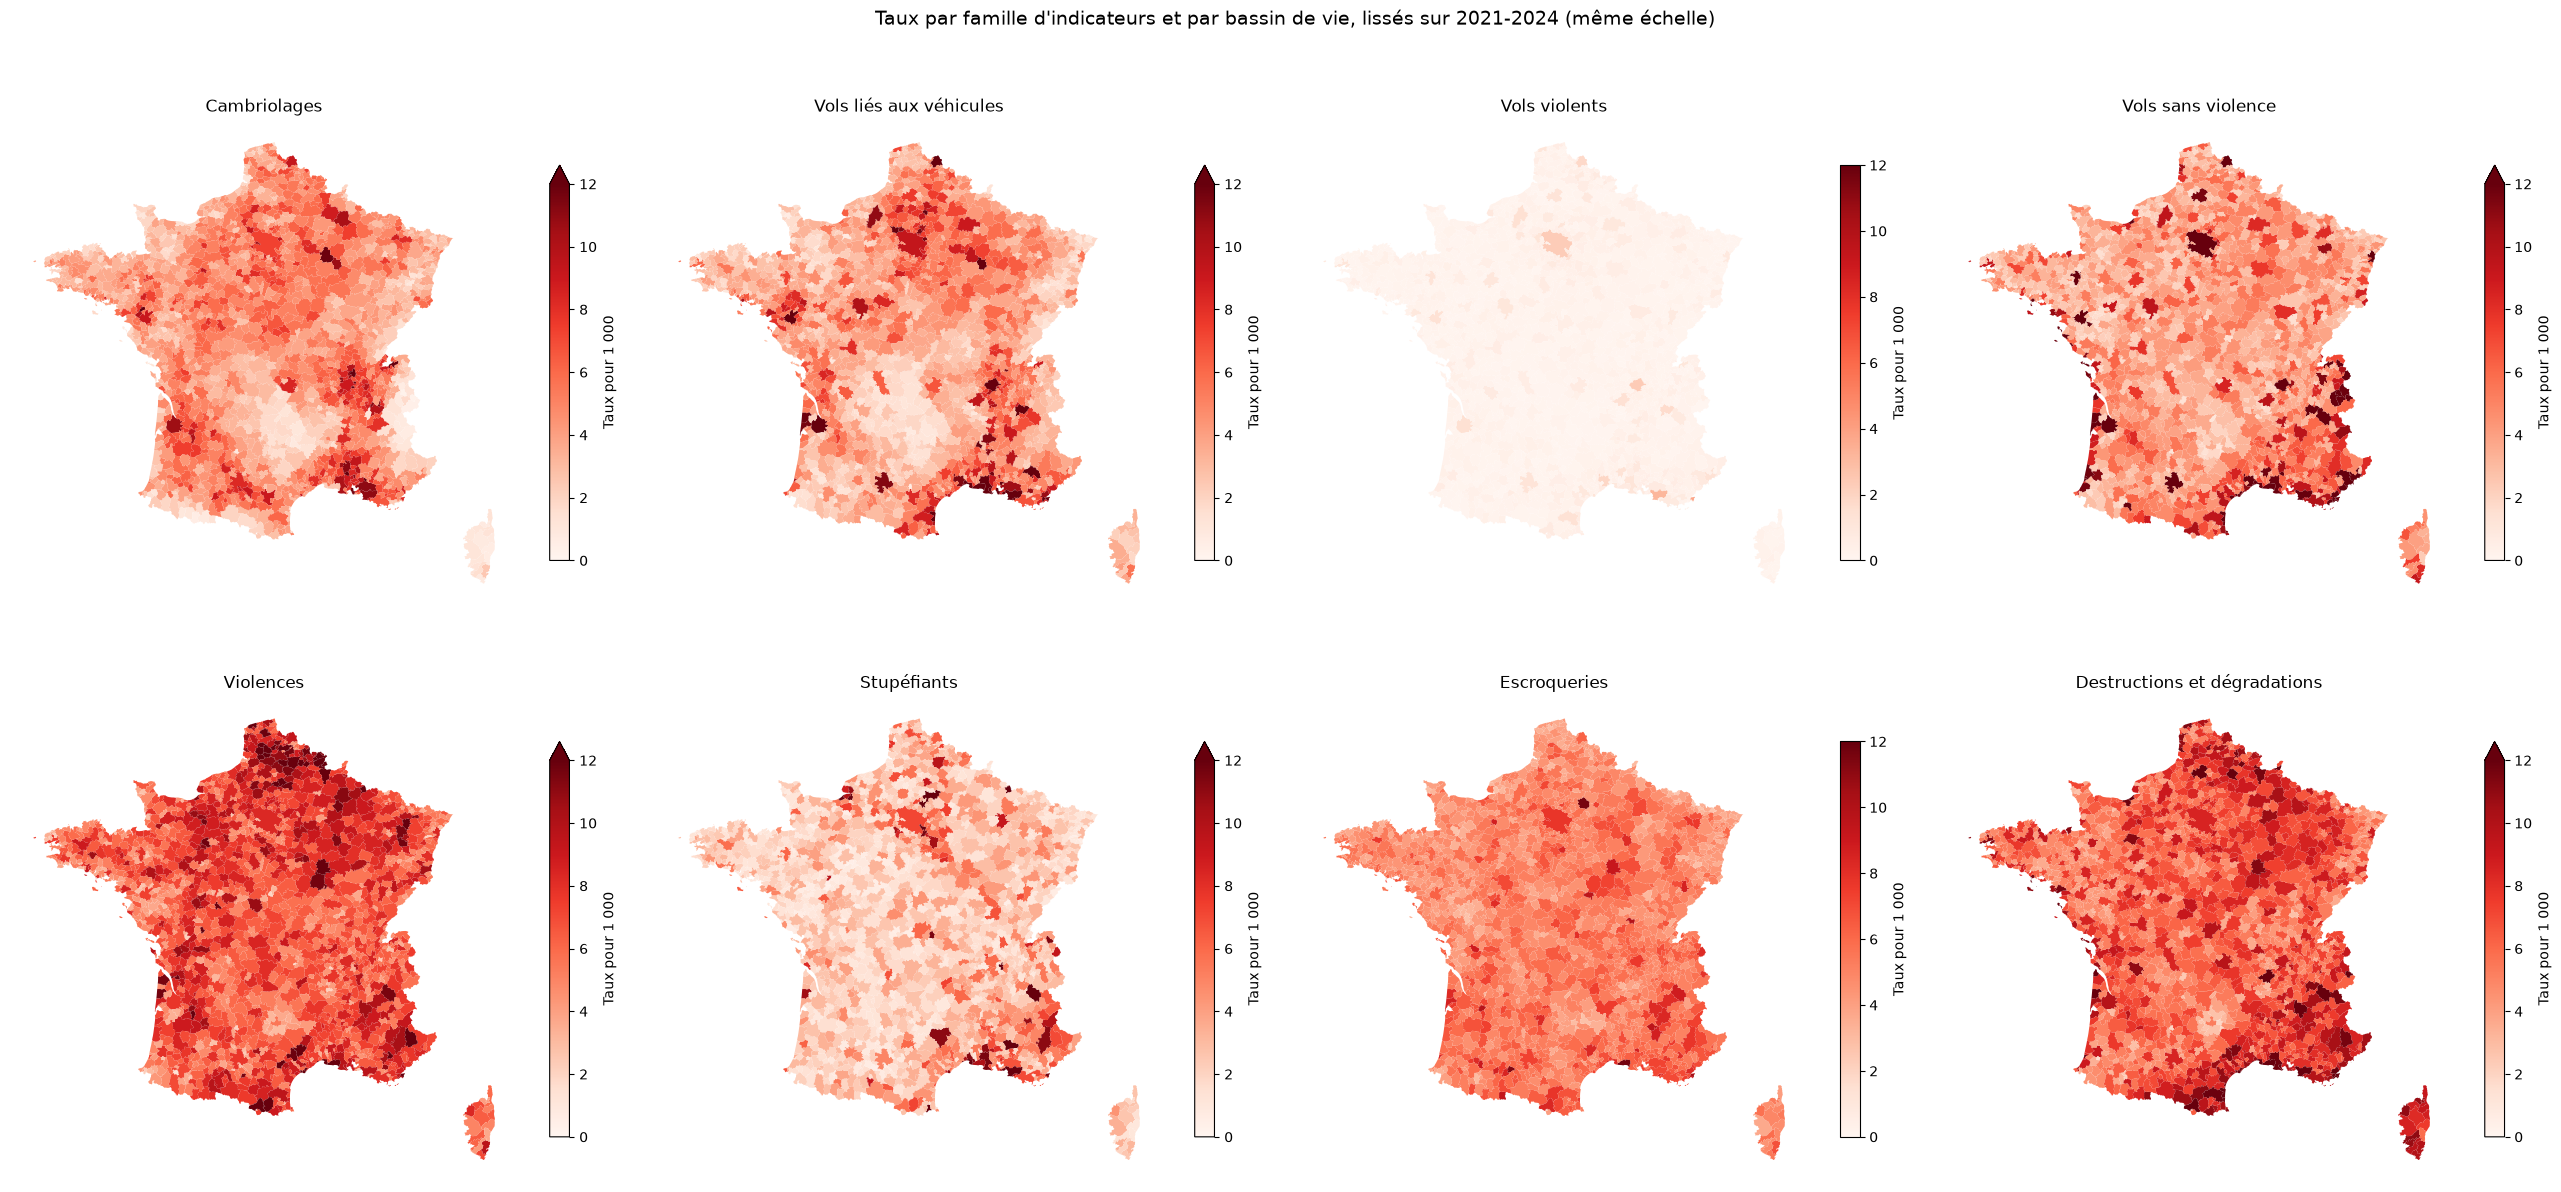

In [9]:
# Taux lissés sur 2021-2024 : somme des faits sur 4 ans / somme des habitants sur 4 ans
l21 = (fam[fam["annee"].between(2021, 2024)]
       .groupby(["maille", "famille"])[["nombre_estime", "denominateur"]].sum())
l21["taux"] = l21["nombre_estime"] / l21["denominateur"] * 1000
l21 = l21.reset_index().pivot(index="maille", columns="famille", values="taux").reset_index()

carte_fam = carte_bv.merge(l21, left_on="BV2022", right_on="maille", how="left")

fig, axes = plt.subplots(2, 4, figsize=(26, 13))
for ax, f in zip(axes.flatten(), liste_familles):
    carte_fam.plot(column=f, cmap="Reds", vmin=0, vmax=12, legend=True, linewidth=0,
                   missing_kwds={"color": "lightgrey"}, ax=ax,
                   legend_kwds={"label": "Taux pour 1 000", "shrink": 0.6})
    ax.set_title(f, fontsize=12)
    ax.set_axis_off()
fig.suptitle("Taux par famille d'indicateurs et par bassin de vie, lissés sur 2021-2024 (même échelle)", fontsize=14)
plt.tight_layout()
plt.show()

**Constat :**
- **Familles qui varient nettement selon le territoire :**
  - **cambriolages** : plus élevés dans le Nord-Est, autour de Paris, dans la vallée du Rhône et autour de Bordeaux, Toulouse et Marseille ; bas dans le Massif central, les Alpes et la Corse ;
  - **vols liés aux véhicules** : élevés dans les grandes agglomérations (Paris, Lyon, Bordeaux, Lille) et sur le littoral méditerranéen ; bas dans le Massif central et l'Ouest ;
  - **stupéfiants** : faibles presque partout, élevés dans quelques grandes villes (Marseille, Paris, Lyon, Lille) ;
  - **violences** : élevées dans le Nord (Hauts-de-France) et sur le pourtour méditerranéen. Réunis, les trois indicateurs de violences forment une géographie plus nette que séparément.
- **Familles élevées presque partout :** destructions et dégradations (plus encore sur le pourtour méditerranéen, dans le Nord-Est et en Corse) et vols sans violence (plus élevés dans les grandes villes, les stations des Alpes et sur le littoral).
- **Famille la plus homogène :** escroqueries, avec des couleurs proches sur tout le territoire.
- **Vols violents** : les taux sont trop bas pour être visibles sur cette échelle (autour de 0,2 pour 1 000).
- La carte lissée sur 2021-2024 est très proche de celle de la seule année 2024 : la géographie de chaque famille est stable.

**Interprétation :** regrouper les indicateurs fait mieux apparaître la géographie des familles peu fréquentes prises une à une, comme les violences ou les vols liés aux véhicules. Plusieurs familles (vols liés aux véhicules, stupéfiants, vols sans violence) sont surtout élevées dans les grandes agglomérations, ce qui rappelle le risque de confusion avec l'effet « ville ».

**Biais / limites :**
- Taux lissés sur 2021-2024. Les cambriolages sont comptés pour 1 000 logements, les autres familles pour 1 000 habitants.
- Effet du nombre : une famille qui additionne plusieurs indicateurs a mécaniquement un taux plus élevé qu'un indicateur seul. Sur une échelle commune, elle paraît donc plus foncée (c'est le cas des violences) : on ne peut pas comparer les niveaux d'une famille à l'autre, seulement la géographie de chacune.
- Dans une famille, l'indicateur le plus fréquent pèse le plus : les violences suivent surtout les violences intrafamiliales, les stupéfiants surtout l'usage.

**Question :** certains indicateurs sont-ils homogènes sur le territoire ? Un indicateur presque identique partout ne peut pas expliquer des différences de prix entre bassins de vie.

In [10]:
# Taux lissés sur 2021-2024 par famille
lisse_fam = (fam[fam["annee"].between(2021, 2024)]
             .groupby(["maille", "famille"])[["nombre_estime", "denominateur"]].sum())
lisse_fam["taux"] = lisse_fam["nombre_estime"] / lisse_fam["denominateur"] * 1000
lisse_fam = lisse_fam.reset_index().pivot(index="maille", columns="famille", values="taux").reset_index()

lisse_fam["dep"] = lisse_fam["maille"].str[:2]   # département du bassin (celui de sa commune pôle)
lisse_fam = lisse_fam[lisse_fam["dep"] != "97"]  # DOM hors périmètre

lignes = []
for f in liste_familles:
    x = lisse_fam[f].dropna()
    d1, med, d9 = x.quantile([0.1, 0.5, 0.9])
    groupes = [g[f].dropna().values for _, g in lisse_fam.groupby("dep")]
    H, p, eta2 = eta2_kruskal(groupes)
    lignes.append({"famille": f, "D1": round(d1, 2), "médiane": round(med, 2), "D9": round(d9, 2),
                   "D9 / D1": round(d9 / d1, 1) if d1 > 0 else np.nan,
                   "p-value": f"{p:.1e}", "η² département": round(eta2, 3)})

display(pd.DataFrame(lignes).set_index("famille").sort_values("η² département", ascending=False))

,D1,médiane,D9,D9 / D1,p-value,η² département
famille,,,,,,
Vols liés aux véhicules,1.86,3.76,6.95,3.7,1.4e-127,0.492
Cambriolages,2.21,4.41,7.14,3.2,2.6e-104,0.416
Vols violents,0.07,0.17,0.45,6.3,5.7e-68,0.294
Escroqueries,3.87,5.05,6.64,1.7,6.2e-59,0.262
Destructions et dégradations,4.19,6.30,9.21,2.2,1.7e-58,0.261
Stupéfiants,1.01,2.21,5.35,5.3,5.1e-56,0.252
Vols sans violence,2.35,3.89,7.40,3.2,1.7e-42,0.203
Violences,4.13,6.55,9.50,2.3,5.0e-37,0.183


**Méthode :** taux lissés sur 2021-2024 (somme des faits sur quatre ans divisée par la somme des habitants), pour limiter l'effet des petits bassins où quelques faits suffisent à faire varier le taux. La période couvre les quatre dernières années hors test ; 2021 est aussi la première année complète des amendes forfaitaires pour usage de stupéfiants. Chaque valeur du tableau est calculée sur les taux des quelque 1 600 bassins de vie de métropole.

**Comment lire le tableau (exemple des cambriolages) :**
- **D1 = 2,21** : 10 % des bassins ont moins de 2,21 cambriolages pour 1 000 logements. Ce sont les bassins les moins touchés.
- **Médiane = 4,41** : la moitié des bassins a moins de 4,41 cambriolages pour 1 000 logements, l'autre moitié plus.
- **D9 = 7,14** : 10 % des bassins ont plus de 7,14 cambriolages pour 1 000 logements. Ce sont les bassins les plus touchés.
- **D9 / D1 = 3,2** : les bassins les plus touchés ont un taux 3,2 fois plus élevé que les moins touchés. Ce rapport mesure **à quel point les bassins sont différents entre eux**. S'il valait 1, tous les bassins auraient le même taux : la famille serait homogène sur le territoire.
- **η² département = 0,42** : 42 % des écarts entre bassins s'expliquent par le département où ils se trouvent. Les 58 % restants viennent de différences entre bassins **d'un même département**. Le η² mesure donc **si les écarts suivent une géographie régionale**. Repères : 0,01 faible, 0,06 moyen, 0,14 fort.
- **p-value** : avec plus de 1 600 bassins, elle est toujours très faible, même pour un écart minime. Ce n'est pas elle qu'on interprète, mais la taille des écarts (D9 / D1) et le η².

**Résultat :**
- **Aucune famille n'est homogène sur le territoire** : le rapport D9 / D1 va de 1,7 à 6,3, et le η² dépasse 0,14 pour les huit familles (effet fort du département).
- **Les vols liés aux véhicules** sont la famille la plus liée à la géographie (η² = 0,49 ; D9 / D1 = 3,7), devant les **cambriolages** (η² = 0,42 ; D9 / D1 = 3,2).
- **Les vols violents** ont des écarts forts entre bassins (D9 / D1 = 6,3), mais restent très rares (médiane de 0,17 pour 1 000) : leurs résultats reposent sur peu de faits.
- **Les stupéfiants** ont aussi de forts écarts (D9 / D1 = 5,3), qui reflètent en partie l'activité des services de police.
- **Les escroqueries** ont les écarts les plus faibles (D9 / D1 = 1,7), mais organisés régionalement (η² = 0,26).
- **Les violences** sont la famille la moins liée à la géographie (η² = 0,18 ; D9 / D1 = 2,3).
- Les résultats sont presque identiques avec un lissage sur 2020-2024 : ils ne dépendent pas de la période choisie.

**Interprétation :** la délinquance enregistrée varie entre bassins de vie pour toutes les familles. Elle est d'autant plus liée à la géographie qu'elle porte sur des biens (véhicules, logements) ; les atteintes aux personnes le sont moins. La carte des violences, très foncée, donnait une impression trompeuse : son taux est élevé parce qu'elle additionne trois indicateurs (effet du nombre), mais ses écarts entre bassins restent modérés. Pour la plupart des familles, la plus grande partie des écarts se joue entre bassins d'un même département, ce qui justifie de travailler au bassin de vie plutôt qu'au département. Les cambriolages, la famille la plus directement liée au logement, font partie des plus variables et des plus territorialisées.

**Biais / limites :**
- Le département d'un bassin est celui de sa commune pôle ; le η² mesure aussi en partie la composition des départements (plus ou moins urbains).
- Dans une famille, l'indicateur le plus fréquent pèse le plus : les violences suivent surtout les violences intrafamiliales, les stupéfiants surtout l'usage.
- Pour les stupéfiants, un même mis en cause peut être compté dans deux communes : l'addition par bassin peut légèrement surestimer le nombre de personnes.

### B3. Évolution dans le temps 

**Pourquoi regarder cela :** le projet porte sur l'évolution des prix. Si la délinquance d'un bassin change peu dans le temps, ou si tous les bassins évoluent de la même façon, elle pourra expliquer les écarts de prix entre bassins, mais difficilement leur évolution.

**Méthode :** en deux temps.
1. **Tendance nationale :** pour chaque famille et chaque année, somme des faits de tous les bassins de métropole divisée par la somme des habitants (des logements pour les cambriolages). Un graphique par famille, avec un axe qui part de 0 pour ne pas exagérer les variations.
2. **Écart de chaque bassin à cette tendance :** évolution du taux du bassin entre 2016-2018 et 2022-2024 (moyennes sur trois ans), moins l'évolution nationale.

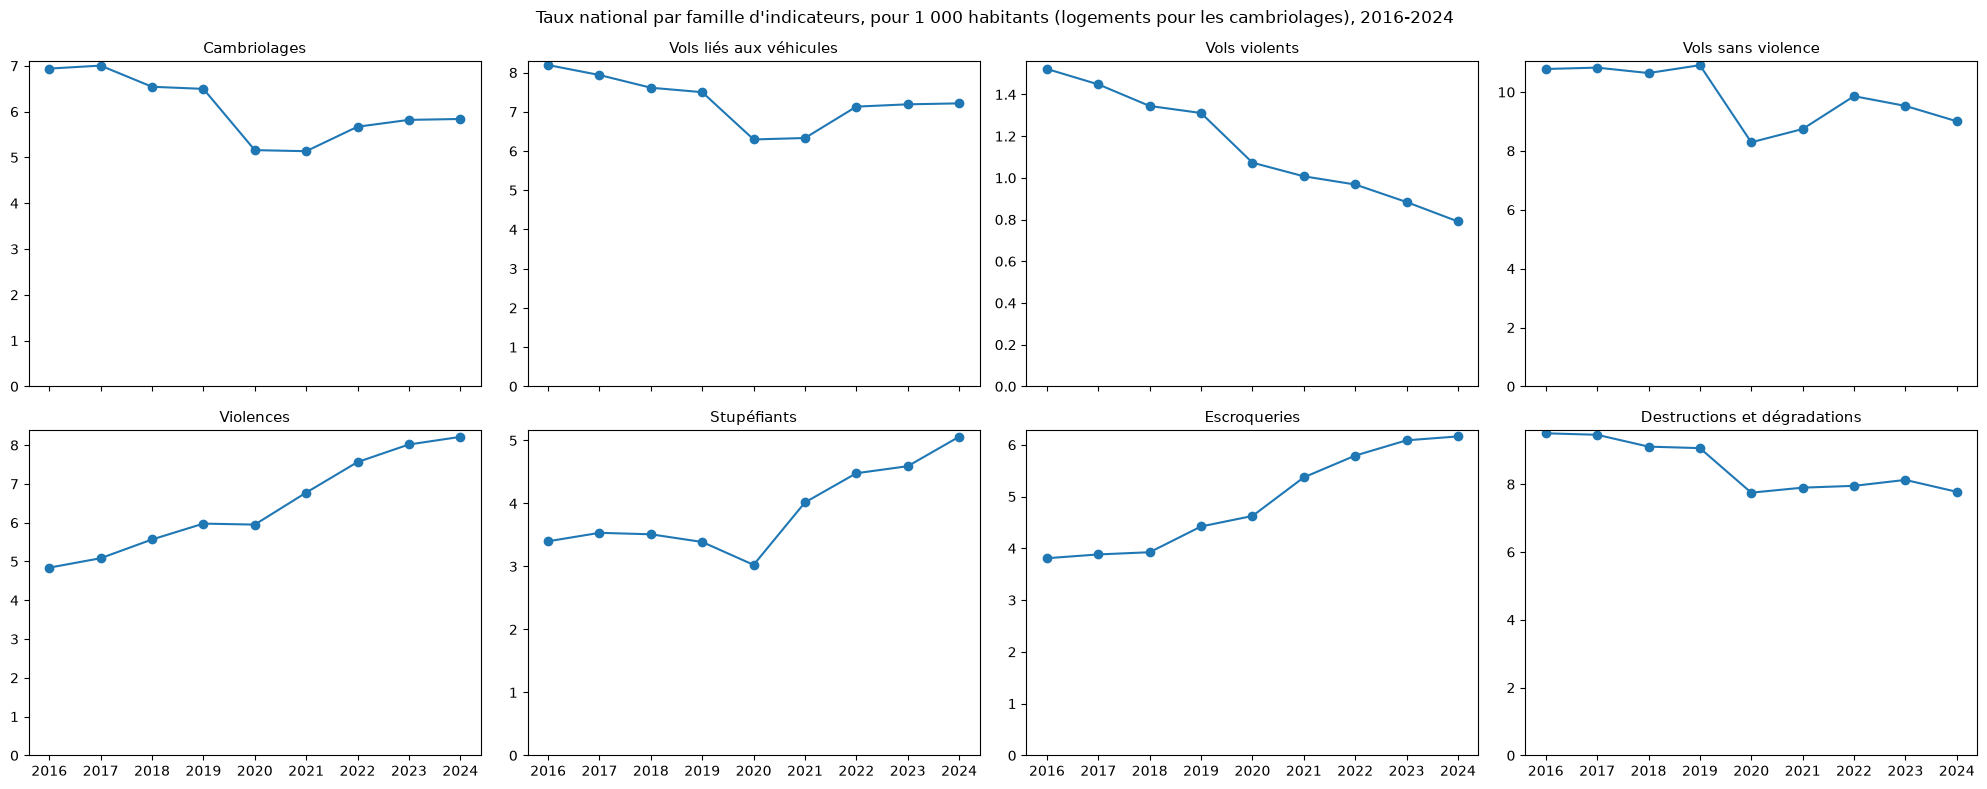

In [11]:
# Bassins de métropole (DOM hors périmètre) ; fam s'arrête déjà en 2024
fam_metro = fam[fam["maille"].str[:2] != "97"]

nat_fam = fam_metro.groupby(["famille", "annee"])[["nombre_estime", "denominateur"]].sum()
nat_fam["taux"] = nat_fam["nombre_estime"] / nat_fam["denominateur"] * 1000
nat_fam = nat_fam.reset_index()

fig, axes = plt.subplots(2, 4, figsize=(20, 8), sharex=True)
for ax, f in zip(axes.flatten(), liste_familles):
    g = nat_fam[nat_fam["famille"] == f]
    ax.plot(g["annee"], g["taux"], marker="o")
    ax.set_title(f, fontsize=11)
    ax.set_ylim(bottom=0)
fig.suptitle("Taux national par famille d'indicateurs, pour 1 000 habitants (logements pour les cambriolages), 2016-2024")
plt.tight_layout()
plt.show()

**Constat :** les familles n'évoluent pas toutes de la même façon entre 2016 et 2024.
- **Hausse continue** : violences, escroqueries, stupéfiants, avec une forte hausse à partir de 2021.
- **Baisse** : vols violents, cambriolages, vols liés aux véhicules, vols sans violence, destructions et dégradations.
- **Une chute en 2020 pour la plupart des familles** : cambriolages, vols liés aux véhicules, vols sans violence, stupéfiants, destructions et dégradations. Les vols liés aux véhicules et les stupéfiants remontent ensuite nettement ; les cambriolages en partie seulement. Les violences, elles, ne baissent pas en 2020 : elles restent au niveau de 2019, puis repartent à la hausse.

**Interprétation :** l'évolution d'une famille ne reflète pas seulement celle de la délinquance. Plusieurs facteurs se mêlent (hypothèses, non vérifiées avec nos données) :
- **Les événements** : la chute de 2020 correspond aux confinements liés à la crise sanitaire (moins de déplacements, plus de présence au domicile, donc moins de vols et de cambriolages). Les dégradations liées au mouvement des gilets jaunes (2018-2019) ne se voient pas dans le taux national : concentrées dans quelques villes, elles pèsent peu face à plus de 500 000 faits par an.
- **La société et le dépôt de plainte** : les victimes de violences sexuelles et intrafamiliales portent plus souvent plainte depuis le mouvement #MeToo (fin 2017) et le Grenelle des violences conjugales (2019). La hausse des violences vient en partie de cette libération de la parole.
- **Les priorités de l'État et des forces de l'ordre** : les stupéfiants comptent des personnes mises en cause, donc ils suivent l'activité des services. La hausse à partir de 2021 suit la création des amendes forfaitaires (fin 2020) et les priorités données à la lutte contre les trafics.
- **La technologie** : les systèmes antivol des voitures rendent les vols de véhicule plus difficiles, ce qui peut expliquer en partie la baisse des vols liés aux véhicules avant 2020.

**Conséquence pour le projet :** ces facteurs agissent au niveau national, sur tous les bassins en même temps. Comme le taux des crédits, ils peuvent expliquer le moment du marché, mais pas les écarts entre bassins. Pour l'évolution des prix, ce qui comptera est la façon dont chaque bassin s'écarte de cette tendance nationale.

Évolution nationale (%) :
 famille
Cambriolages                   -15.4
Destructions et dégradations   -15.0
Escroqueries                    55.3
Stupéfiants                     35.3
Violences                       53.6
Vols liés aux véhicules         -9.3
Vols sans violence             -12.0
Vols violents                  -38.8
dtype: float64


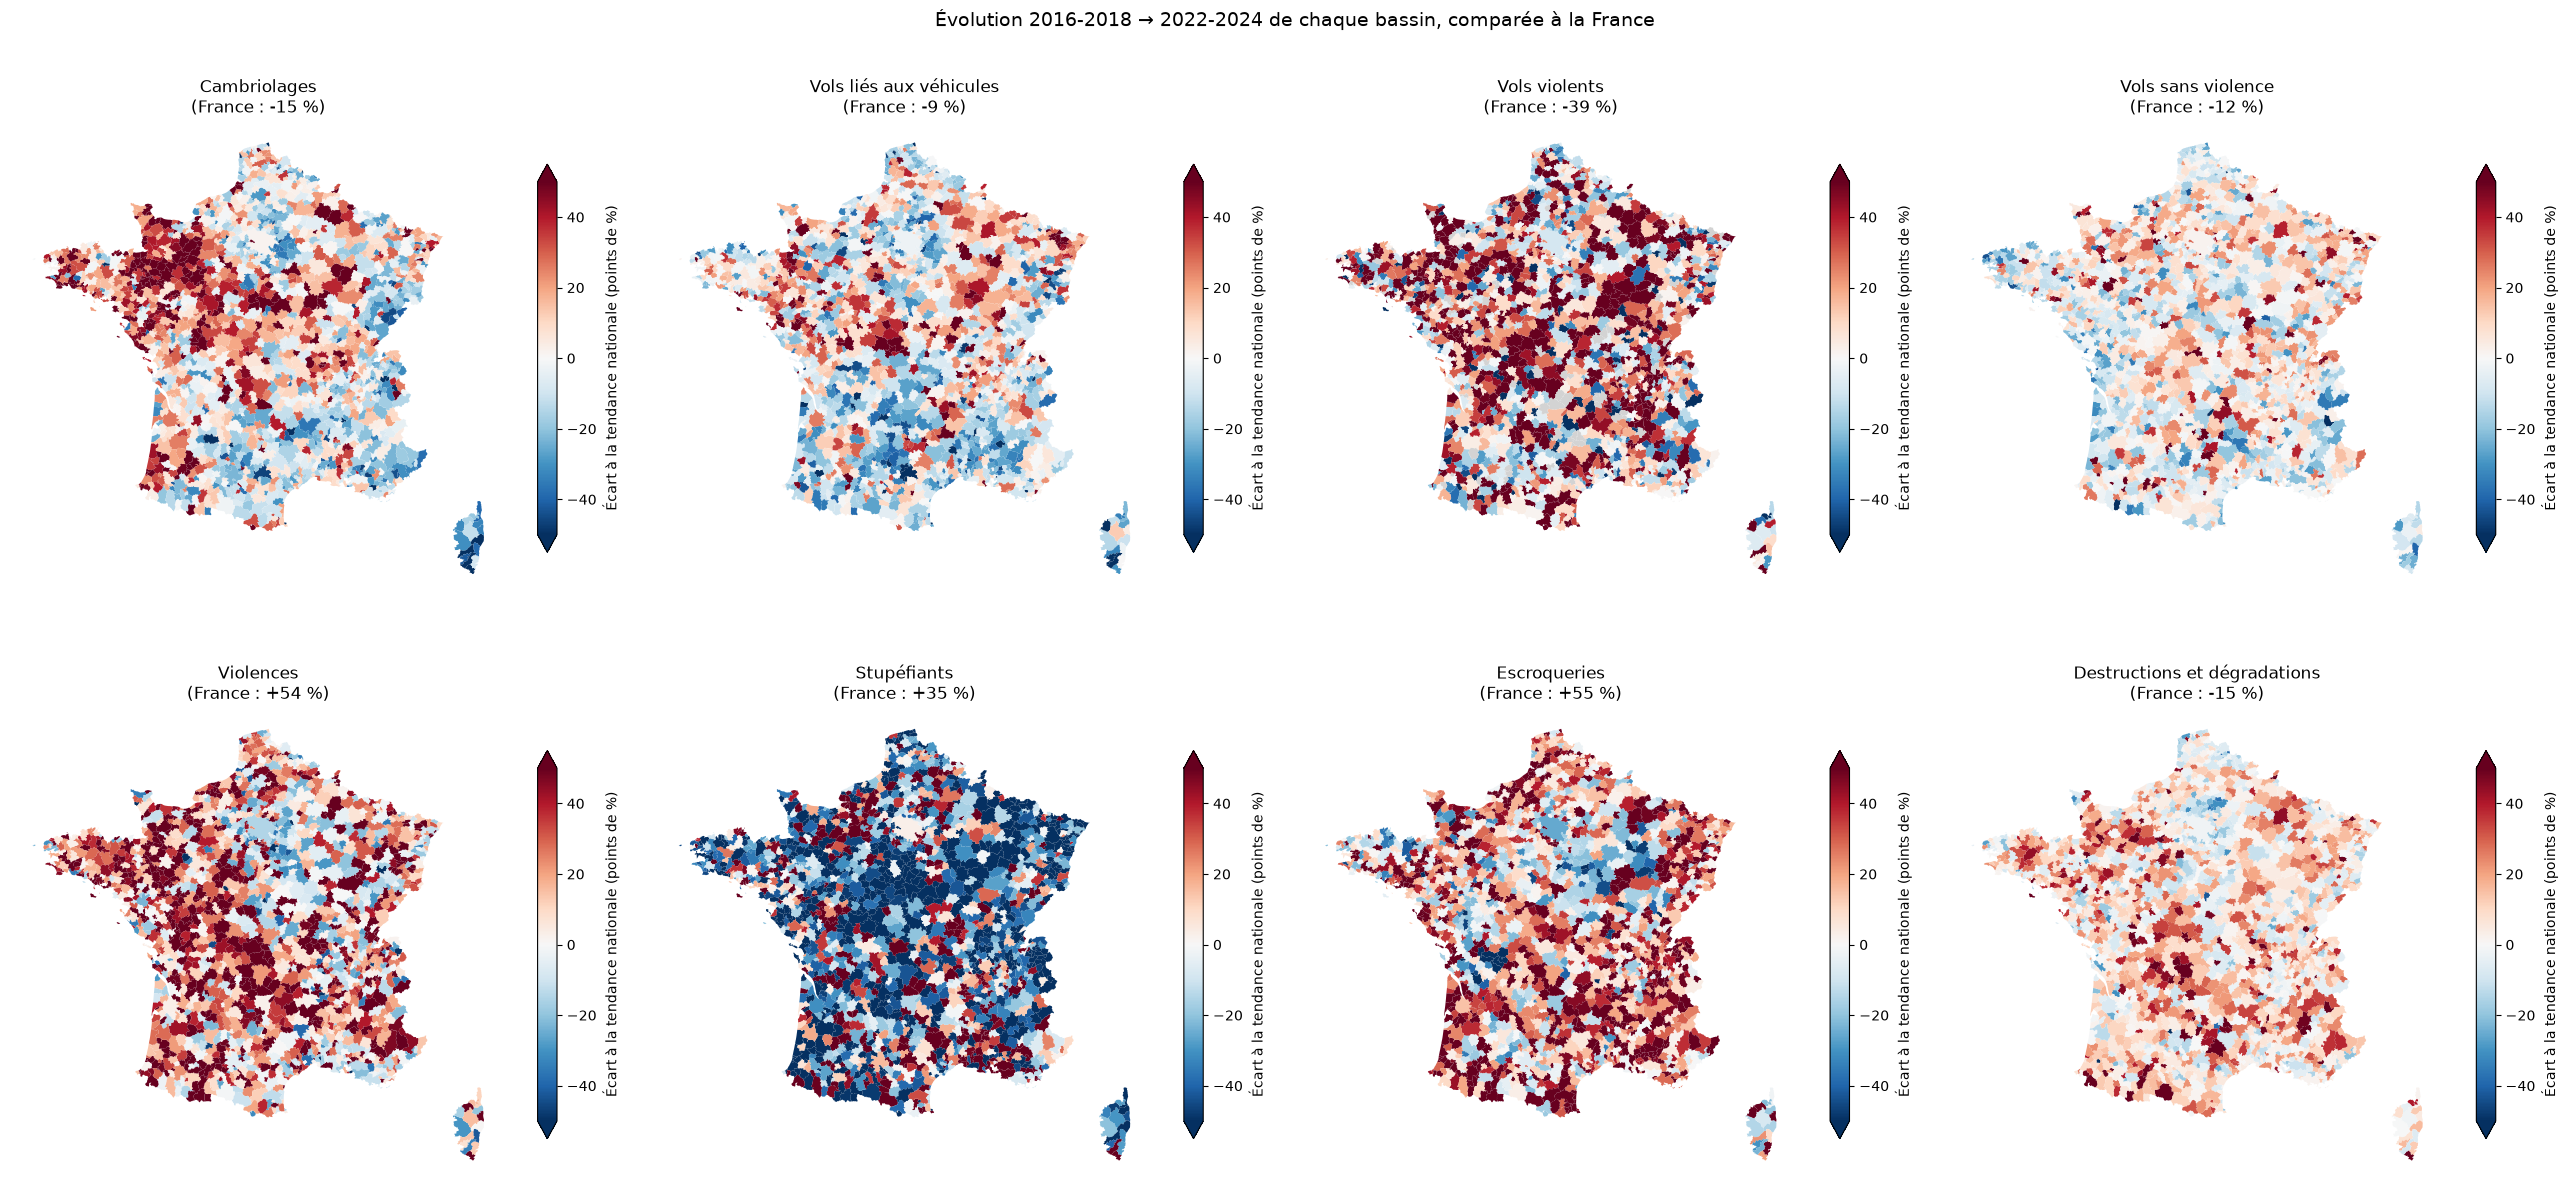

In [12]:
# Évolution de chaque bassin entre 2016-2018 et 2022-2024 (%)
evol_fam = pd.DataFrame({"debut": taux_periode(fam_metro, 2016, 2018, ["maille", "famille"]),
                         "fin": taux_periode(fam_metro, 2022, 2024, ["maille", "famille"])}).reset_index()
evol_fam["evol_bv"] = (evol_fam["fin"] / evol_fam["debut"] - 1) * 100
evol_fam["evol_bv"] = evol_fam["evol_bv"].replace([np.inf, -np.inf], np.nan)   # aucun fait au départ : évolution impossible

# Évolution nationale de chaque famille (%)
evol_nat_fam = (taux_periode(fam_metro, 2022, 2024, "famille") / taux_periode(fam_metro, 2016, 2018, "famille") - 1) * 100
print("Évolution nationale (%) :\n", evol_nat_fam.round(1))

# Écart du bassin à la tendance nationale (points de %)
evol_fam["ecart"] = evol_fam["evol_bv"] - evol_fam["famille"].map(evol_nat_fam)
ecart_fam = evol_fam.pivot(index="maille", columns="famille", values="ecart").reset_index()
carte_ecart_fam = carte_bv.merge(ecart_fam, left_on="BV2022", right_on="maille", how="left")

fig, axes = plt.subplots(2, 4, figsize=(26, 13))
for ax, f in zip(axes.flatten(), liste_familles):
    carte_ecart_fam.plot(column=f, cmap="RdBu_r", vmin=-50, vmax=50, legend=True, linewidth=0,
                         missing_kwds={"color": "lightgrey"}, ax=ax,
                         legend_kwds={"label": "Écart à la tendance nationale (points de %)", "shrink": 0.6})
    ax.set_title(f"{f}\n(France : {evol_nat_fam[f]:+.0f} %)", fontsize=12)
    ax.set_axis_off()
fig.suptitle("Évolution 2016-2018 → 2022-2024 de chaque bassin, comparée à la France", fontsize=14)
plt.tight_layout()
plt.show()

**Constat :**
- **Cambriolages** (France : −15 %) : les écarts forment de grandes zones. Les cambriolages ont augmenté, dans l'Ouest (Bretagne, Normandie, Pays de la Loire) et une partie du Centre ; ils ont baissé plus vite dans le Sud-Est et en Corse.
- **Vols liés aux véhicules** (France : −9 %) : baisse plus forte que la moyenne dans une grande partie du Sud ; évolution plus défavorable dans des zones du Centre et du Nord-Est.
- **Vols sans violence** (−12 %) et **destructions et dégradations** (−15 %) : la plupart des bassins suivent la tendance nationale, avec des écarts faibles.
- **Vols violents** (−39 %) et **violences** (+54 %) : la majorité des bassins a évolué plus défavorablement que la France (en rouge).
- **Stupéfiants** (+35 %) : la majorité des bassins a évolué nettement en dessous de la tendance nationale (en bleu).
- **Escroqueries** (+55 %) : les écarts forment une mosaïque, sans organisation géographique.

**Interprétation :**
- Quand la plupart des bassins sont du même côté de la tendance nationale, cette tendance est portée par quelques grandes agglomérations, qui pèsent beaucoup dans le total national. Les vols violents ont surtout baissé, et les stupéfiants surtout augmenté, dans les grandes villes.
- Les cambriolages et les vols liés aux véhicules évoluent différemment selon les régions, avec des zones cohérentes. Ce sont les familles les plus susceptibles d'expliquer des écarts d'évolution des prix entre bassins.
- Pour les escroqueries, la mosaïque peut venir du hasard dans les petits bassins ou de pratiques locales de dépôt de plainte, plutôt que d'une vraie dynamique territoriale.

**Biais / limites :**
- La tendance nationale est dominée par les grandes agglomérations : elle ne décrit pas l'évolution d'un bassin typique. La médiane des évolutions des bassins serait une autre référence possible.
- L'écart est mesuré en points de pourcentage, avec la même échelle pour toutes les familles : pour une famille à forte tendance nationale (violences, escroqueries), un même écart représente une différence relative plus faible.
- Pour les vols violents, les faits sont rares : dans les petits bassins, l'évolution peut venir du hasard.

### B4. Stabilité des bassins dans le temps

**Variables :** les taux des 8 familles par bassin de vie et par année, 2016-2024.

**Pourquoi regarder cela :** si la délinquance d'un bassin est une caractéristique stable (un bassin très touché le reste), elle décrit surtout **quel** bassin, comme une réputation, et peu **quand**. Elle pourrait alors expliquer le niveau des prix, mais difficilement leur évolution.

**Méthode :** pour chaque famille :
1. **Nuage de points** du taux de chaque bassin en 2016-2018 (abscisse) et en 2022-2024 (ordonnée), en échelles logarithmiques, avec une diagonale qui marque « même taux au début et à la fin ».
2. **Les bassins gardent-ils leur rang ?** Corrélation de Spearman entre les taux lissés de 2016-2018 et ceux de 2022-2024. Proche de 1, les bassins les plus touchés au début le sont encore à la fin.
3. **D'où viennent les écarts ?** Part des écarts entre toutes les valeurs (bassin × année) qui vient des différences entre bassins, plutôt que de l'évolution dans le temps.

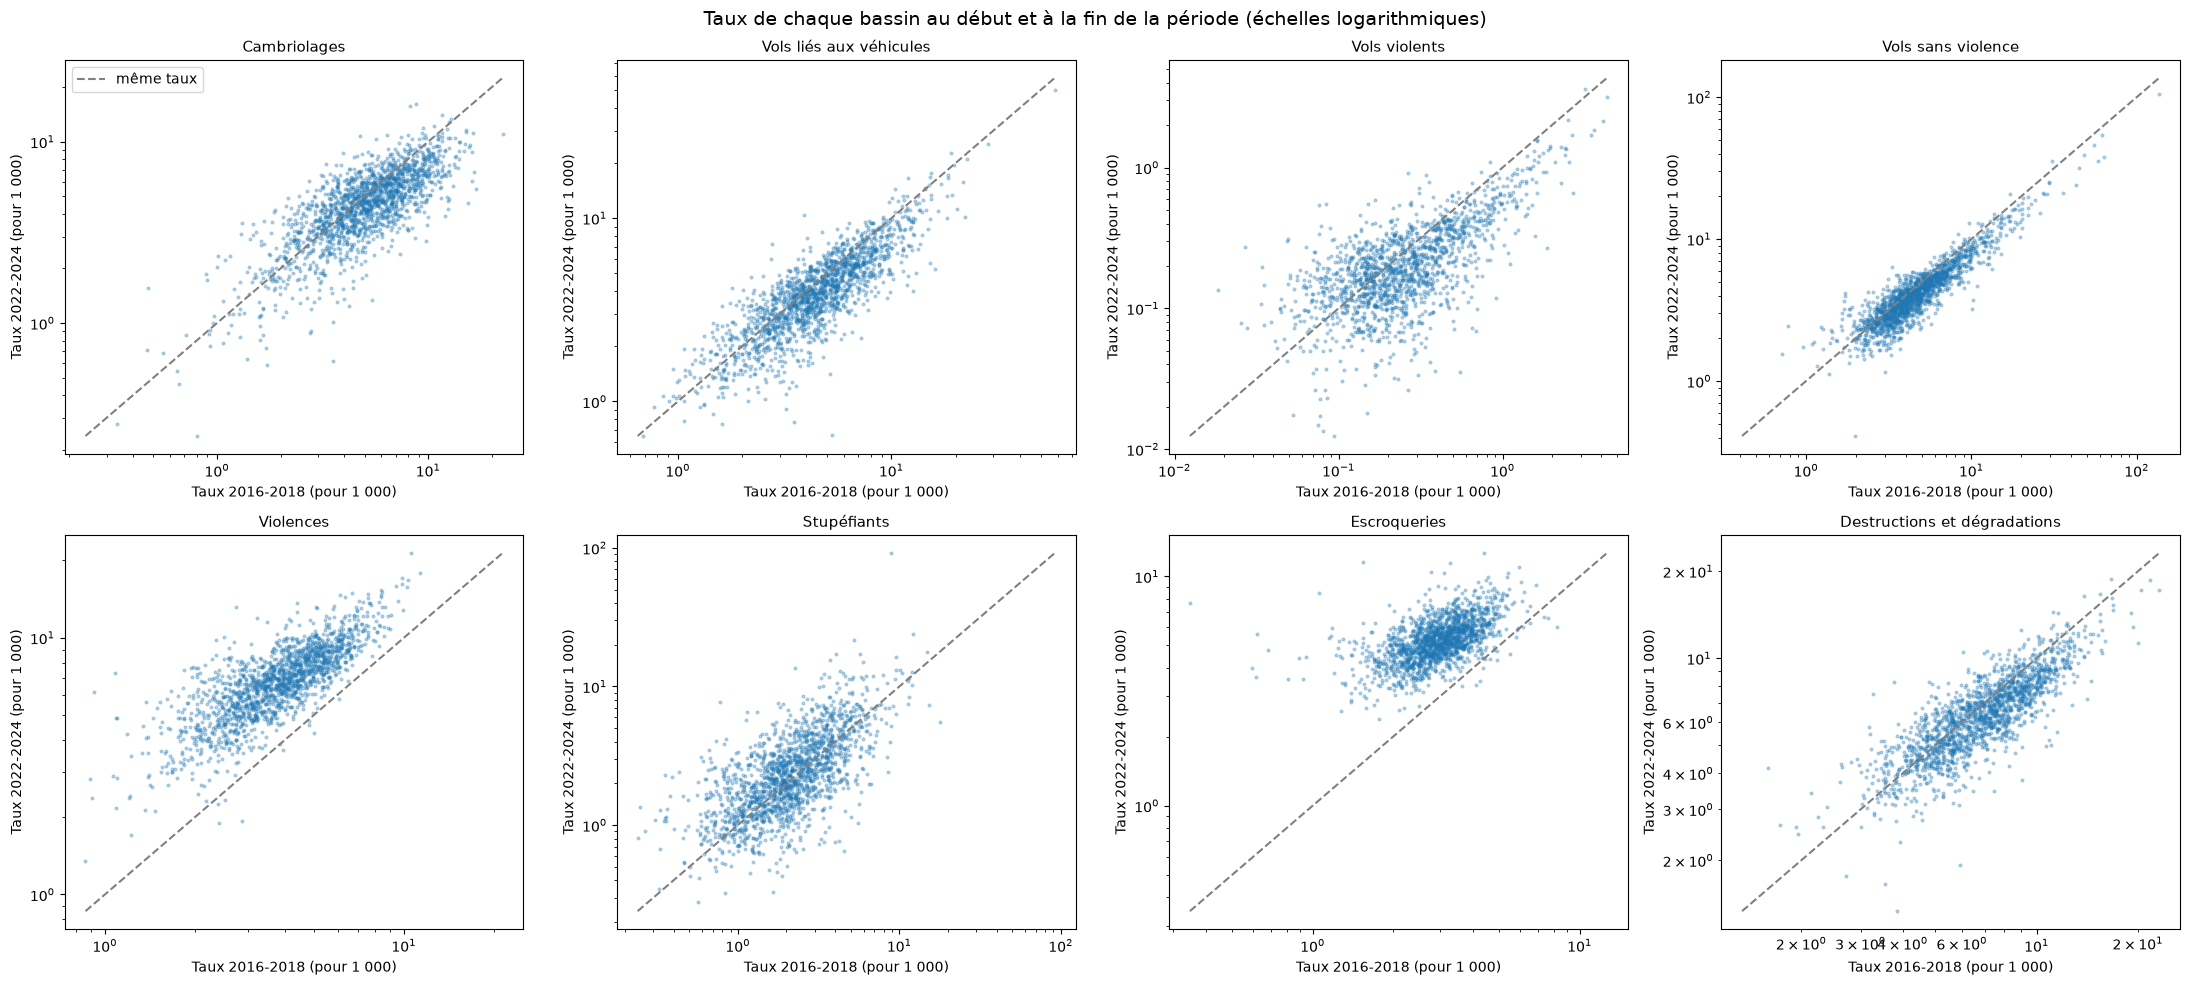

In [13]:
debut = taux_periode(fam_metro, 2016, 2018, ["maille", "famille"]).unstack("famille")
fin = taux_periode(fam_metro, 2022, 2024, ["maille", "famille"]).unstack("famille")

fig, axes = plt.subplots(2, 4, figsize=(22, 10))
for ax, f in zip(axes.flatten(), liste_familles):
    d = pd.concat([debut[f], fin[f]], axis=1, keys=["debut", "fin"]).dropna()
    d = d[(d["debut"] > 0) & (d["fin"] > 0)]          # échelle logarithmique : pas de taux nul
    ax.scatter(d["debut"], d["fin"], s=4, alpha=0.3)
    lim = [d.min().min(), d.max().max()]
    ax.plot(lim, lim, color="grey", linestyle="--", label="même taux")
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_title(f, fontsize=11)
    ax.set_xlabel("Taux 2016-2018 (pour 1 000)")
    ax.set_ylabel("Taux 2022-2024 (pour 1 000)")
axes[0, 0].legend()
fig.suptitle("Taux de chaque bassin au début et à la fin de la période (échelles logarithmiques)", fontsize=14)
plt.tight_layout()
plt.show()

In [14]:
# Taux de métropole par bassin et par année (DOM hors périmètre)
tf = taux_fam[taux_fam["maille"].str[:2] != "97"]


lignes = []
for f in liste_familles:
    # 1. Les bassins gardent-ils leur rang ?
    d = pd.concat([debut[f], fin[f]], axis=1, keys=["debut", "fin"]).dropna()
    rho, p = stats.spearmanr(d["debut"], d["fin"])

    # 2. Part des écarts due aux différences entre bassins (plutôt qu'au temps)
    large = tf.pivot(index="maille", columns="annee", values=f).dropna()   # une ligne par bassin, une colonne par année
    total = large.stack().var()
    entre = large.mean(axis=1).var()

    lignes.append({"famille": f, "rho 2016-18 / 2022-24": round(rho, 2), "p-value": f"{p:.1e}",
                   "part entre bassins (%)": round(entre / total * 100, 1), "n bassins": len(d)})

display(pd.DataFrame(lignes).set_index("famille"))

,rho 2016-18 / 2022-24,p-value,part entre bassins (%),n bassins
famille,,,,
Cambriolages,0.74,3.5e-295,70.2,1681
Vols liés aux véhicules,0.83,0.0e+00,84.2,1681
Vols violents,0.59,9.9e-159,83.0,1681
Vols sans violence,0.88,0.0e+00,89.2,1681
Violences,0.79,0.0e+00,57.6,1681
Stupéfiants,0.66,7.7e-210,62.7,1681
Escroqueries,0.58,2.5e-151,36.1,1681
Destructions et dégradations,0.83,0.0e+00,81.0,1681


**Constat :**
- **Graphiques :** pour les vols sans violence, les destructions et dégradations et les vols liés aux véhicules, les points forment une bande étroite le long de la diagonale : chaque bassin garde presque le même taux. Pour les vols violents, les escroqueries et les stupéfiants, le nuage est plus dispersé. Pour les violences et les escroqueries, le nuage est entièrement au-dessus de la diagonale : hausse dans presque tous les bassins.
- **Tableau :**

| Profil | Familles | rho début / fin | Part des écarts entre bassins |
|---|---|---|---|
| Caractéristique stable du bassin | Vols sans violence, vols liés aux véhicules, destructions et dégradations | 0,83 à 0,88 | 81 à 89 % |
| Plutôt stable, avec des bassins qui bougent | Cambriolages | 0,74 | 70 % |
| Rang instable, faits rares | Vols violents | 0,59 | 83 % |
| Tendance dans le temps importante | Violences, stupéfiants, escroqueries | 0,58 à 0,79 | 36 à 63 % |

Pour toutes les familles, la p-value est inférieure à 0,05 : les taux du début et de la fin sont liés.

**Interprétation :**
- **Vols sans violence, vols liés aux véhicules, destructions et dégradations** sont des caractéristiques stables des bassins : un bassin très touché le reste. Ils décrivent surtout **où** l'on est, comme une réputation. Ils pourront expliquer le niveau des prix, plus difficilement leur évolution, sauf si le niveau de délinquance est lié à des trajectoires de prix différentes (hypothèse à tester en partie C).
- **Les cambriolages** sont en grande partie stables, mais les bassins changent davantage de position : c'est cohérent avec les évolutions différentes selon les régions (Ouest, Sud-Est) vues sur les cartes d'écart. C'est la famille qui peut le mieux porter à la fois le « où » et le « quand ».
- **Pour les violences et surtout les escroqueries** (36 % seulement des écarts entre bassins), la hausse nationale domine : ces familles disent surtout **quand**, au niveau national (libération de la parole, fraude en ligne), plutôt que quel bassin.
- **Pour les vols violents**, le rang instable vient probablement du faible nombre de faits : dans un petit bassin, quelques faits suffisent à le faire changer de place.

**Biais / limites :** les bassins sans aucun fait sont retirés des graphiques (échelles logarithmiques), mais pris en compte dans le rho. Le rho compare deux périodes de trois ans, et non toutes les années.

# C. Relation avec la cible

### C0. Rapprochement avec la table cible

**Sources et rapprochement :** table cible au bassin de vie (prix médian au m² par bassin × année, construite plus haut) et taux de délinquance par famille, par `maille` + `annee`, de 2016 à 2024.

**Pourquoi regarder cela :** avant toute analyse, il faut mesurer quelle part des bassins et des ventes trouve un taux de délinquance.

**Méthode :** jointure à gauche (on garde toutes les lignes de la cible), puis comptage des lignes et des ventes sans délinquance.

In [17]:
# Cible sur les années communes aux deux sources (pas de délinquance communale avant 2016)
c = cible_bv[cible_bv["annee"].between(2016, 2024)].copy()
c["n_total"] = c["n_appart"] + c["n_maison"]

# Jointure à gauche : on garde tous les bassins × années de la cible
fusion = c.merge(taux_fam, on=["maille", "annee"], how="left", indicator=True)

bilan = fusion.groupby("_merge", observed=True).agg(lignes=("maille", "size"), ventes=("n_total", "sum"))
bilan["% lignes"] = (bilan["lignes"] / bilan["lignes"].sum() * 100).round(1)
bilan["% ventes"] = (bilan["ventes"] / bilan["ventes"].sum() * 100).round(1)
display(bilan)

,lignes,ventes,% lignes,% ventes
_merge,,,,
both,14517,7600276,100.0,100.0


**Constat :** les 14 517 lignes bassin × année de la cible (2016-2024) et les 7 600 276 ventes correspondantes trouvent toutes un taux de délinquance. Les deux tables utilisent la même table de correspondance et la même maille : aucune perte au rapprochement.

### C1. Prix au m² selon le niveau de délinquance

**Variables :** taux des 8 familles lissés sur 2016-2024 ; prix médian au m² des maisons et des appartements sur 2016-2024, par bassin de vie.

**Pourquoi regarder cela :** les bassins où la délinquance enregistrée est plus élevée ont-ils des prix différents ? C'est la question du **niveau** ; l'évolution sera traitée en C2.

**Méthode :** prix médian recalculé à partir des ventes de 2021-2024 (une médiane ne se combine pas). Bassins avec au moins 30 ventes du type de bien sur la période. Nuages de points pour les maisons, puis corrélation de Spearman pour les deux types de biens.

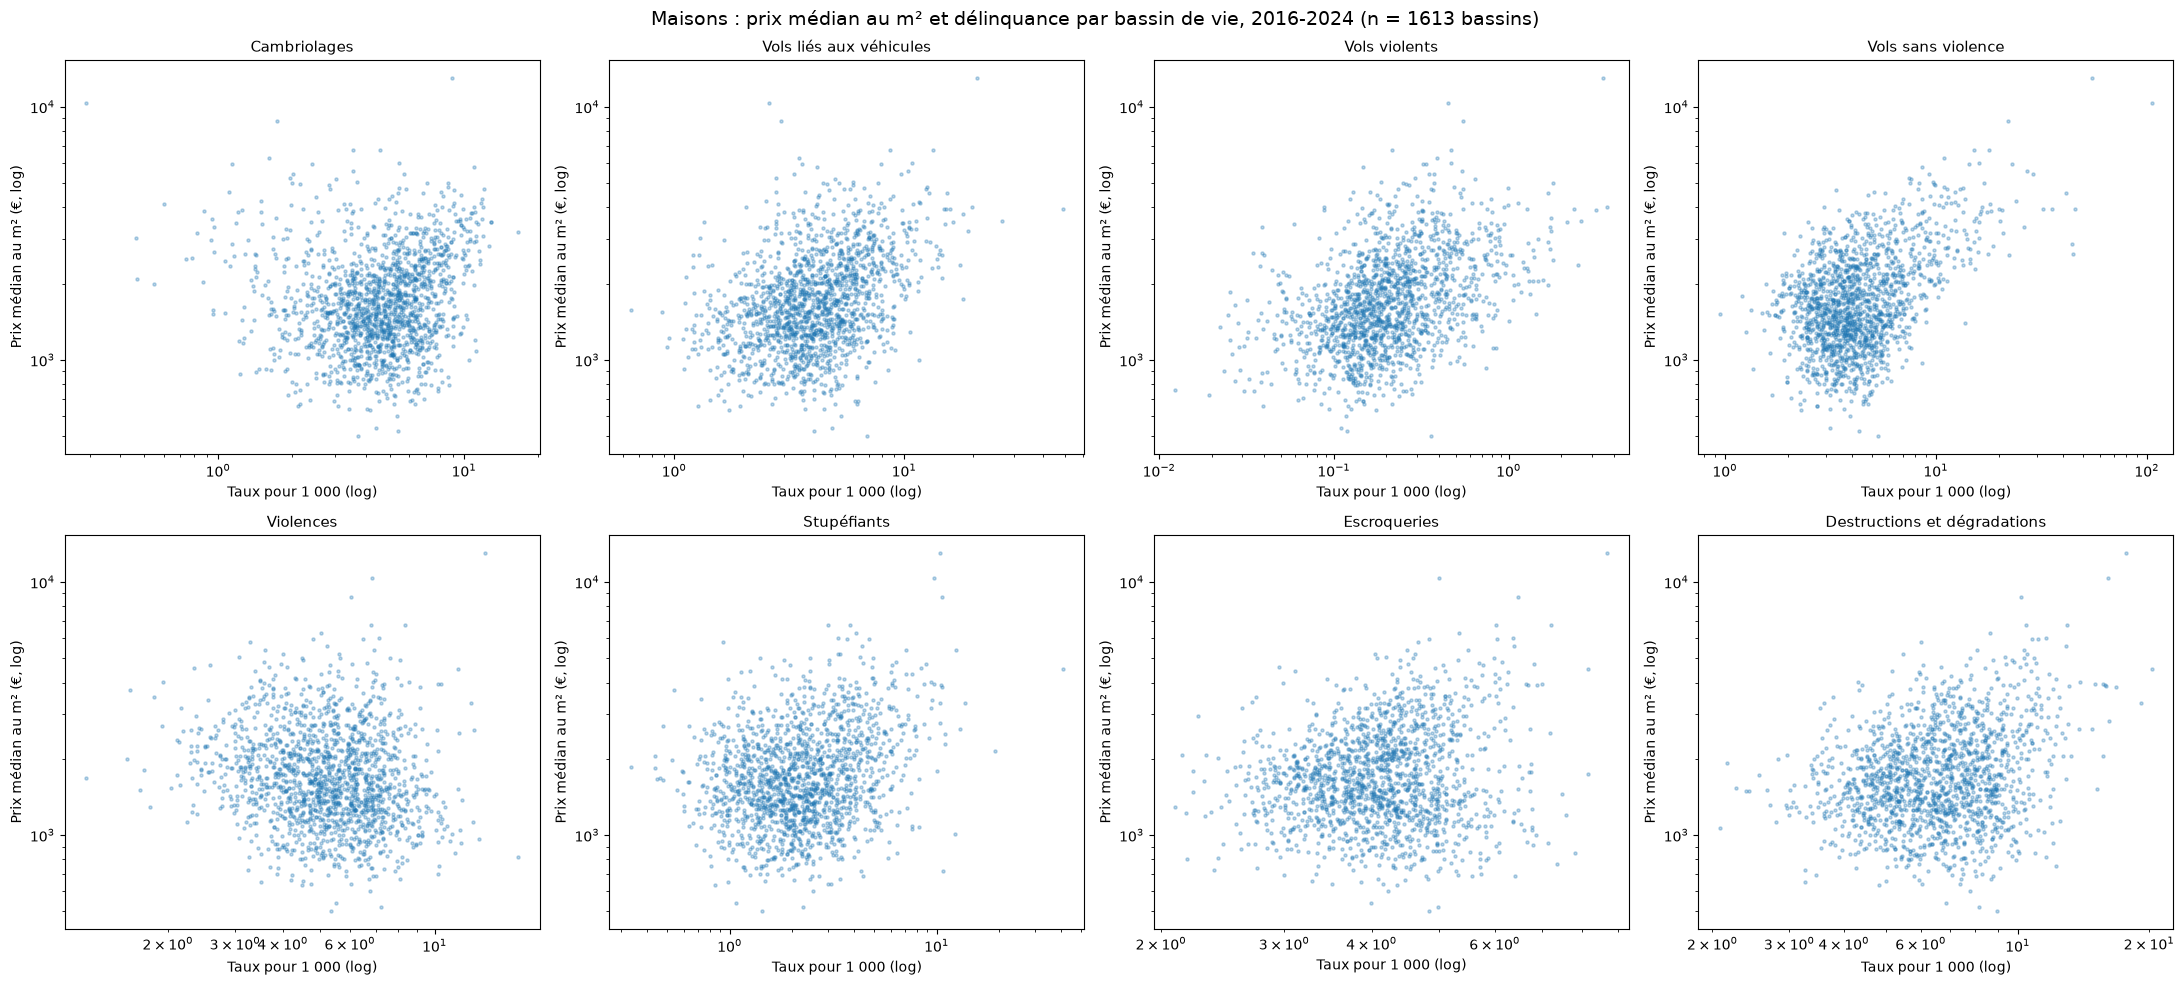

,rho maisons,rho appartements
,,
CAMBRIOLAGES,0.18,0.10
VOLS LIÉS AUX VÉHICULES,0.37,0.28
↳ Vols de véhicule,0.28,0.21
↳ Vols dans les véhicules,0.50,0.34
↳ Vols d'accessoires sur véhicules,0.08,0.10
VOLS VIOLENTS,0.44,0.32
↳ Vols avec armes,0.33,0.23
↳ Vols violents sans arme,0.41,0.31
VOLS SANS VIOLENCE,0.34,0.29


Bassins : maisons 1613 | appartements 1207


In [24]:
# Prix médian au m² par bassin et par type de bien, sur les ventes de 2016-2024
prix_p = (pop[pop["anneemut"].between(2016, 2024)]
          .groupby(["maille", "type_bien"])["prix_m2"]
          .agg(n="count", prix="median").reset_index())
prix_p = prix_p[prix_p["n"] >= 30]   # assez de ventes pour une médiane fiable

# Taux lissés sur la même période (2016-2024)
taux_p = taux_periode(fam, 2016, 2024, ["maille", "famille"]).unstack("famille").reset_index()

c1 = prix_p.merge(taux_p, on="maille", how="inner")

# Nuages de points : maisons
m = c1[c1["type_bien"] == "maison"]
fig, axes = plt.subplots(2, 4, figsize=(22, 10))
for ax, f in zip(axes.flatten(), liste_familles):
    ax.scatter(m[f], m["prix"], s=5, alpha=0.3)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_title(f, fontsize=11)
    ax.set_xlabel("Taux pour 1 000 (log)")
    ax.set_ylabel("Prix médian au m² (€, log)")
fig.suptitle(f"Maisons : prix médian au m² et délinquance par bassin de vie, 2016-2024 (n = {len(m)} bassins)", fontsize=14)
plt.tight_layout()
plt.show()

# Taux par indicateur lissés sur 2016-2024 (pour les sous-lignes du tableau)
taux_ind = (delinq_bv[delinq_bv["annee"].between(2016, 2024)]
            .groupby(["maille", "indicateur"])[["nombre_estime", "denominateur"]].sum())
taux_ind["taux"] = taux_ind["nombre_estime"] / taux_ind["denominateur"] * 1000
taux_ind = taux_ind.reset_index().pivot(index="maille", columns="indicateur", values="taux").reset_index()
c1_ind = prix_p.merge(taux_ind, on="maille", how="inner")

def rho_prix(df, col):
    """rho de Spearman entre une colonne de taux et le prix, pour les maisons et les appartements."""
    res = {}
    for t, nom in [("maison", "rho maisons"), ("appart", "rho appartements")]:
        d = df[df["type_bien"] == t]
        res[nom] = round(stats.spearmanr(d[col], d["prix"], nan_policy="omit")[0], 2)
    return res

# Indicateurs de chaque famille ; l'AFD est montré à part car il fait déjà partie de l'usage
sous_lignes = {f: [i for i, fam_i in familles.items() if fam_i == f] for f in liste_familles}
sous_lignes["Stupéfiants"].append("Usage de stupéfiants (AFD)")

lignes = []
for f in liste_familles:
    lignes.append({"": f.upper(), **rho_prix(c1, f)})                # ligne de la famille
    if len(sous_lignes[f]) > 1:                                      # sous-lignes si plusieurs indicateurs
        for ind in sous_lignes[f]:
            nom = "dont AFD (compris dans l'usage)" if "AFD" in ind else ind
            lignes.append({"": "   ↳ " + nom, **rho_prix(c1_ind, ind)})

tableau = pd.DataFrame(lignes).set_index("")
display(tableau.style.format("{:.2f}").set_properties(**{"text-align": "left"}))
print("Bassins : maisons", (c1["type_bien"] == "maison").sum(), "| appartements", (c1["type_bien"] == "appart").sum())



**Comment lire le tableau (exemple : cambriolages, appartements, rho = 0,10) :**
- **Ce que mesure rho :** la corrélation de Spearman indique si deux variables évoluent dans le même sens. On classe les bassins selon leur taux de cambriolages, puis selon leur prix au m², et on compare les deux classements.
- **Le signe :** rho positif signifie que les bassins plus touchés ont plutôt des prix plus élevés ; négatif, plutôt des prix plus bas.
- **La valeur :** rho va de −1 à 1. Repères : 0,1 lien faible, 0,3 moyen, 0,5 fort. Avec 0,10, le lien est faible : connaître le taux de cambriolages d'un bassin ne dit presque rien de son prix.
- **Un ordre de grandeur :** rho² donne approximativement la part des écarts de classement liée à l'autre variable : 0,10² ≈ 1 % ; 0,50² = 25 %.
- **La p-value :** avec plus de 1 000 bassins, elle est inférieure à 0,05 même pour un lien très faible. C'est rho qu'on interprète.
- **Lignes en majuscules :** la famille d'indicateurs. **Lignes ↳ :** chaque indicateur de la famille, pris séparément.

**Constat :**
- Les nuages de points sont très dispersés : à taux de délinquance égal, les prix varient fortement d'un bassin à l'autre.
- **Les vols vont avec des prix plus élevés** : vols violents (rho = 0,44 pour les maisons), vols liés aux véhicules (0,37), vols sans violence (0,34). Le lien le plus fort concerne les vols dans les véhicules (0,50 pour les maisons, lien fort).
- **Les violences vont avec des prix plus bas** (famille : −0,17 et −0,21), surtout les violences sexuelles (−0,36 et −0,30) et intrafamiliales (−0,25 et −0,24). Les violences hors cadre familial ne sont pas liées au prix (0,02 et −0,10).
- **Les cambriolages, les escroqueries, les destructions et les stupéfiants** ont des liens faibles (rho de 0,10 à 0,22). Dans les stupéfiants, la partie sanctionnée par amende (AFD) est plus liée au prix (0,37) que l'usage dans son ensemble (0,21).
- Les liens sont en général un peu plus forts pour les maisons (1 613 bassins) que pour les appartements (1 207 bassins).

**Résultat :** pour toutes les familles, la p-value est inférieure à 0,05 : on rejette H0. Les liens sont faibles à moyens au niveau des familles (|rho| ≤ 0,44) ; seul un indicateur atteint un lien fort (vols dans les véhicules, maisons).

**Le regroupement peut masquer des liens :**
- il renforce le lien pour les vols violents : la famille (0,44) dépasse ses deux indicateurs (0,41 et 0,33), car additionner des faits rares réduit le hasard ;
- il le dilue pour les vols liés aux véhicules, où les vols d'accessoires ne sont pas liés au prix (0,08), et pour les violences, où les violences hors cadre familial ne le sont pas non plus (0,02). Les violences sexuelles, les moins nombreuses des trois, pèsent peu dans la somme alors que leur lien est le plus net.

**Interprétation :**
- Le lien positif des vols avec les prix reflète probablement l'effet « ville » : ces faits sont plus fréquents dans les grandes agglomérations, qui sont aussi les plus chères.
- Le lien négatif des violences sexuelles et intrafamiliales va dans le sens d'un effet de réputation. Il peut aussi refléter le niveau de vie des habitants, plus modeste dans ces bassins.
- Les cambriolages, attendus comme les plus liés au logement, ont un lien faible avec le niveau des prix.

**Avis métier :** il s'agit d'associations, pas de causes. Les cambriolages visent plutôt les secteurs aisés ; la délinquance de voie publique se concentre là où il y a du passage ; les prix bas attirent des ménages modestes. La délinquance et les prix dépendent tous deux de la nature du territoire.

**Biais / limites :**
- Une valeur par bassin sur 2016-2024 : l'analyse compare des bassins, pas des moments.
- Le bassin de vie mélange des quartiers très différents : la réputation joue souvent à une échelle plus fine.
- L'effet « ville » n'est pas contrôlé.
- Les familles ont été construites sur la nature des faits : pour la modélisation, les violences et les vols liés aux véhicules pourraient être découpés plus finement.

### C2. Évolution des prix selon le niveau de délinquance

**Pourquoi regarder cela :** le projet porte sur l'évolution des prix. On se demande si les bassins les plus touchés par la délinquance au début de la période ont connu une évolution des prix différente des autres (effet de réputation).

**Méthode :** pour chaque famille, les bassins sont classés en 4 groupes de même taille selon leur taux de délinquance de 2016-2018, des moins touchés aux plus touchés. Pour chaque groupe, prix médian au m² en 2016-2018 et en 2021-2023, recalculé à partir des ventes. Bassins avec au moins 30 ventes du type de bien dans chaque période. Les graphiques portent sur les maisons (1 609 bassins) ; le test porte sur les maisons et les appartements (858 bassins).

Évolution nationale du prix au m² (%) : {'maison': np.float64(19.3), 'appart': np.float64(19.6)}


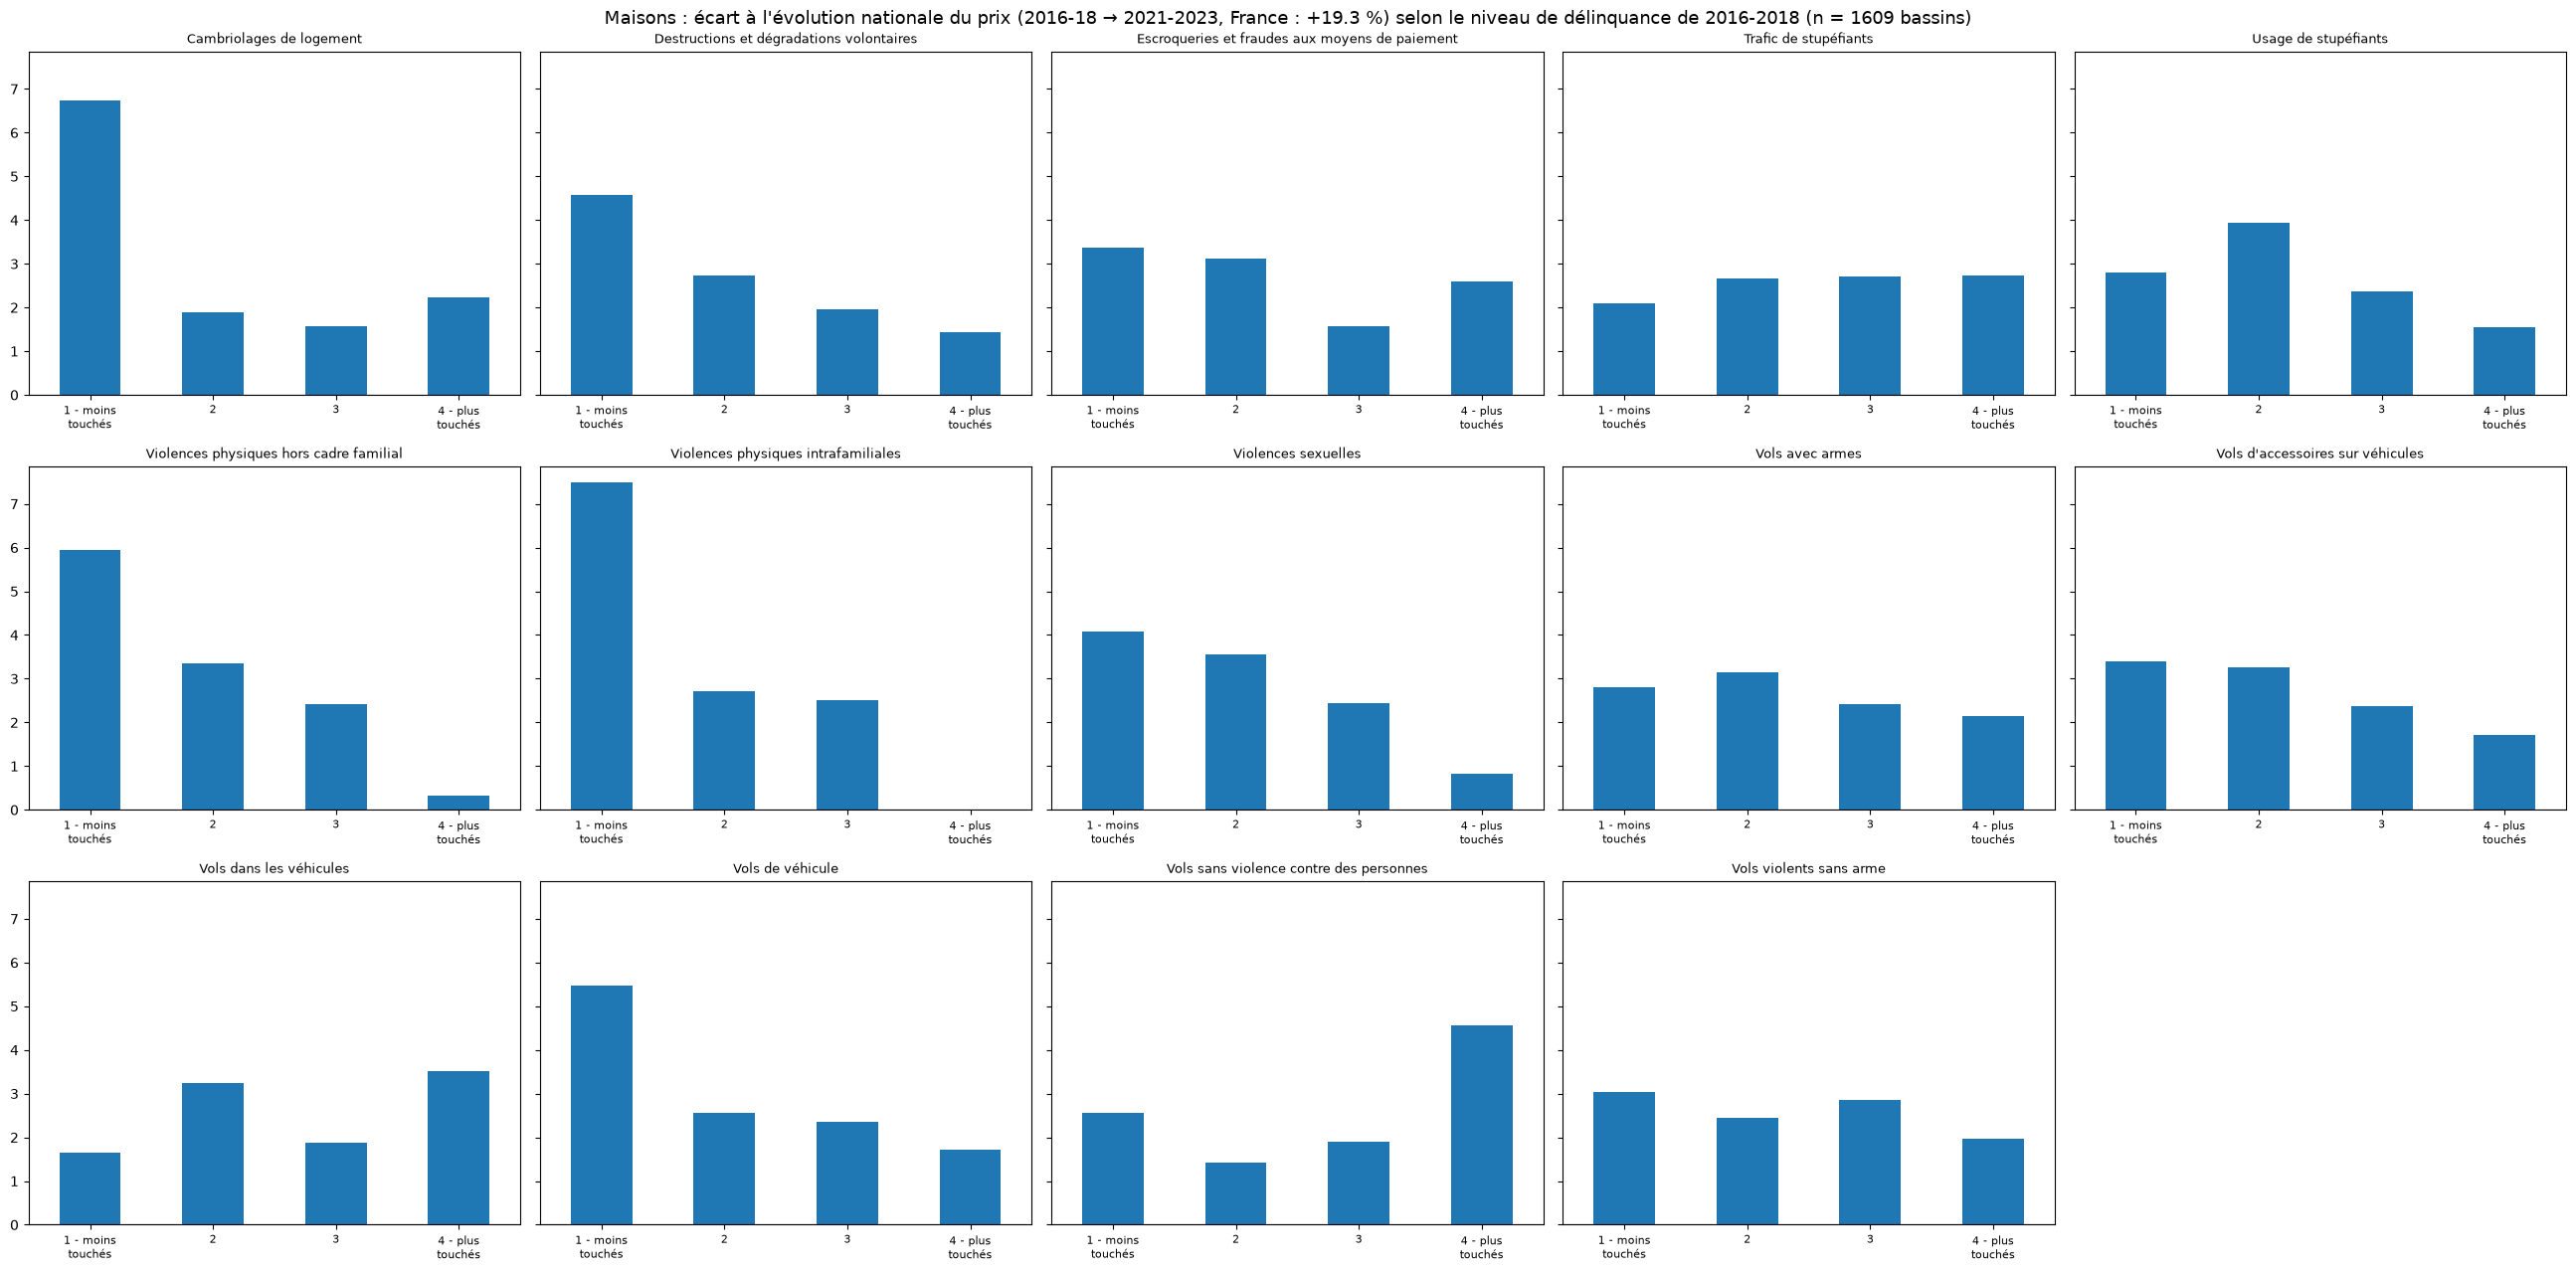

In [41]:
# 1. Prix médian au m² d'une période, par bassin et type de bien (recalculé à partir des ventes)
def prix_periode(debut, fin):
    p = (pop[pop["anneemut"].between(debut, fin)]
         .groupby(["maille", "type_bien"])["prix_m2"].agg(n="count", prix="median"))
    return p[p["n"] >= 30]["prix"]

c2 = pd.concat([prix_periode(2016, 2018), prix_periode(2021, 2023)],
               axis=1, keys=["prix_debut", "prix_fin"]).dropna().reset_index()

# 2. Évolution du prix de chaque bassin entre 2016-2018 et 2021-2023 (%)
c2["evol_prix"] = (c2["prix_fin"] / c2["prix_debut"] - 1) * 100

# 3. Évolution nationale par type de bien : médiane de toutes les ventes de chaque période
nat = {}
for t in ["maison", "appart"]:
    v = pop[pop["type_bien"] == t]
    nat[t] = (v.loc[v["anneemut"].between(2021, 2023), "prix_m2"].median()
              / v.loc[v["anneemut"].between(2016, 2018), "prix_m2"].median() - 1) * 100
print("Évolution nationale du prix au m² (%) :", {k: round(x, 1) for k, x in nat.items()})

# 4. Évolution relative : écart du bassin à l'évolution nationale (points de %)
c2["evol_relative"] = c2["evol_prix"] - c2["type_bien"].map(nat)

# 5. Taux de délinquance de départ (2016-2018) par indicateur, bassins de métropole
ind_depart = (delinq_bv[delinq_bv["annee"].between(2016, 2018) & (delinq_bv["maille"].str[:2] != "97")]
              .groupby(["maille", "indicateur"])[["nombre_estime", "denominateur"]].sum())
ind_depart["taux"] = ind_depart["nombre_estime"] / ind_depart["denominateur"] * 1000
ind_depart = ind_depart.reset_index().pivot(index="maille", columns="indicateur", values="taux").reset_index()

c2_ind = c2[["maille", "type_bien", "evol_relative"]].merge(ind_depart, on="maille", how="inner")

# AFD exclu : les amendes forfaitaires n'existent pas en 2016-2018 (taux nul partout)
liste_ind = [c for c in ind_depart.columns if c not in ["maille", "Usage de stupéfiants (AFD)"]]
groupes_q = ["1 - moins\ntouchés", "2", "3", "4 - plus\ntouchés"]

# 6. Graphiques : 4 groupes de bassins selon le taux de départ, écart médian à l'évolution nationale
def barres_relatives_ind(type_bien, nom):
    d = c2_ind[c2_ind["type_bien"] == type_bien].copy()
    fig, axes = plt.subplots(3, 5, figsize=(26, 13), sharey=True)
    for ax, ind in zip(axes.flatten(), liste_ind):
        d["groupe"] = pd.qcut(d[ind].rank(method="first"), 4, labels=groupes_q)
        med = d.groupby("groupe", observed=True)["evol_relative"].median()
        med.plot.bar(ax=ax, color=["tab:blue" if v >= 0 else "tab:orange" for v in med])
        ax.axhline(0, color="black", linewidth=0.8)
        ax.set_title(ind, fontsize=9)
        ax.set_xlabel("")
        ax.tick_params(axis="x", rotation=0, labelsize=8)
    axes.flatten()[-1].set_visible(False)   # 14 indicateurs pour 15 cases
    fig.suptitle(f"{nom} : écart à l'évolution nationale du prix (2016-18 → 2021-2023, France : {nat[type_bien]:+.1f} %) "
                 f"selon le niveau de délinquance de 2016-2018 (n = {len(d)} bassins)", fontsize=13)
    plt.tight_layout()
    plt.show()

barres_relatives_ind("maison", "Maisons")

**Comment lire les graphiques :** chaque barre est l'évolution relative médiane d'un groupe de bassins, c'est-à-dire l'écart entre l'évolution de leur prix et l'évolution nationale (+19,3 % pour les maisons), en points de %. Exemple : une barre à 7 signifie que la moitié des bassins du groupe ont progressé d'au moins 7 points de plus que la France (au moins +26 % au lieu de +19 %). Si les barres baissent de gauche à droite, les bassins les plus touchés par la délinquance au départ ont vu leurs prix progresser moins vite. Toutes les barres sont positives parce que l'évolution nationale est dominée par les grandes agglomérations, où les prix ont moins augmenté : seule la comparaison entre groupes compte.

**Constat (maisons) :**
- **Violences** (intrafamiliales, hors cadre familial, sexuelles) et **destructions et dégradations** : les barres baissent régulièrement des moins touchés aux plus touchés. Pour les violences intrafamiliales, les bassins les moins touchés ont progressé d'environ 7,5 points de plus que la France, les plus touchés comme la France.
- **Cambriolages et vols de véhicule** : les bassins les moins touchés ont nettement mieux progressé que les autres groupes (environ +6,7 et +5,5 points, contre +2 à +2,5 pour les autres).
- **Vols violents, vols d'accessoires, usage de stupéfiants** : légère baisse des moins touchés aux plus touchés.
- **Vols sans violence, vols dans les véhicules, trafic de stupéfiants, escroqueries** : pas de profil net ; pour les vols sans violence, les plus touchés progressent même davantage.

**Hypothèse :** plus un bassin est touché par certaines formes de délinquance au départ (violences, destructions, cambriolages, vols de véhicule), moins ses prix progressent par rapport à la tendance nationale (effet de réputation).

**Méthode de vérification :** pour chaque indicateur et chaque type de bien, corrélation de Spearman entre le taux de délinquance de 2016-2018 et l'évolution relative du prix, calculée sur tous les bassins (et non sur les 4 groupes). Un rho négatif confirme l'hypothèse.

In [42]:
# Corrélation de Spearman entre le taux de départ et l'évolution relative du prix, par indicateur
lignes = []
for ind in liste_ind:
    ligne = {"indicateur": ind}
    for t, nom in [("maison", "maisons"), ("appart", "appartements")]:
        d = c2_ind[c2_ind["type_bien"] == t]
        rho, p = stats.spearmanr(d[ind], d["evol_relative"], nan_policy="omit")
        ligne[f"rho {nom}"] = round(rho, 2)
        ligne[f"p-value {nom}"] = f"{p:.1e}"
    lignes.append(ligne)

display(pd.DataFrame(lignes).set_index("indicateur").sort_values("rho maisons"))
print("Bassins : maisons", (c2_ind["type_bien"] == "maison").sum(),
      "| appartements", (c2_ind["type_bien"] == "appart").sum())

,rho maisons,p-value maisons,rho appartements,p-value appartements
indicateur,,,,
Violences physiques intrafamiliales,-0.27,2.8e-29,-0.26,1.6e-14
Violences physiques hors cadre familial,-0.20,4.8e-16,-0.19,1.7e-08
Violences sexuelles,-0.17,1.5e-11,-0.09,7.2e-03
Cambriolages de logement,-0.14,2.5e-08,-0.18,1.1e-07
Vols de véhicule,-0.11,1.2e-05,-0.22,1.4e-10
Destructions et dégradations volontaires,-0.10,6.0e-05,-0.06,9.1e-02
Vols d'accessoires sur véhicules,-0.07,2.7e-03,-0.09,8.1e-03
Usage de stupéfiants,-0.07,5.9e-03,-0.09,8.0e-03
Escroqueries et fraudes aux moyens de paiement,-0.06,1.4e-02,0.00,9.9e-01


Bassins : maisons 1609 | appartements 858


**Comment lire le tableau (exemple : violences physiques intrafamiliales, maisons, rho = −0,27) :**
- **Ce que mesure rho :** la corrélation de Spearman compare deux classements des bassins : selon leur taux de violences intrafamiliales en 2016-2018, et selon l'évolution relative de leur prix.
- **Le signe :** négatif signifie que plus un bassin était touché au départ, moins ses prix ont progressé par rapport à la France. C'est le sens de l'hypothèse.
- **La valeur :** repères 0,1 lien faible, 0,3 moyen, 0,5 fort. Avec −0,27, le lien est faible, proche de moyen. rho² ≈ 0,07 : environ 7 % des écarts de classement sont liés au taux de départ.
- **La p-value :** inférieure à 0,05, le lien n'est probablement pas dû au hasard. Au-dessus de 0,05 (par exemple vols avec armes, maisons : p = 0,15), on ne peut pas conclure à un lien. Avec plus de 800 bassins, une p-value faible ne dit pas que le lien est important : c'est rho qu'on interprète.

**Résultat :**
- **Les violences ont les liens négatifs les plus nets**, pour les deux types de biens : violences intrafamiliales (rho = −0,27 pour les maisons, −0,26 pour les appartements), hors cadre familial (−0,20 et −0,19), sexuelles (−0,17 et −0,09).
- **Les cambriolages et les vols de véhicule** ont des liens négatifs faibles (cambriolages : −0,14 et −0,18 ; vols de véhicule : −0,11 et −0,22).
- **Les vols avec armes** ne sont liés à l'évolution relative que pour les appartements (−0,19 ; maisons : non significatif).
- **Les destructions et dégradations** ont un lien très faible pour les maisons (−0,10) et non significatif pour les appartements.
- **Les vols sans violence** ont un lien légèrement positif (0,09 et 0,10) ; le trafic de stupéfiants, les vols violents sans arme et les escroqueries n'ont pas de lien.

L'hypothèse est **en partie confirmée** : pour les violences, les cambriolages et les vols de véhicule, les bassins les plus touchés au départ ont vu leurs prix progresser moins vite que les autres. Mais tous les liens sont faibles (|rho| ≤ 0,27).

**Interprétation :** les graphiques en barres montraient des écarts nets entre groupes, alors que les rho sont faibles. Les deux résultats sont compatibles : les barres comparent les médianes de groupes de 400 bassins, tandis que rho tient compte de la forte dispersion entre bassins d'un même groupe. Les graphiques montrent aussi que l'écart vient surtout du groupe des bassins les moins touchés, qui a nettement mieux progressé que les autres. Le niveau de délinquance de départ apporte donc une information sur l'évolution des prix, mais faible : il ne peut pas, à lui seul, expliquer pourquoi un bassin progresse plus qu'un autre.

**Avis métier :** le résultat va dans le sens d'un effet de réputation pour les violences. Mais les bassins les moins touchés sont souvent ruraux ou de petites villes, qui ont connu une forte demande après la crise sanitaire : une partie de l'écart peut venir de l'opposition entre rural et urbain plutôt que de la délinquance elle-même.

# Synthèse

| Constat majeur | Preuve | Conséquence projet | Action |
|---|---|---|---|
| Les 15 indicateurs se regroupent en 8 familles de même nature | B1 : liens de 0,4 à 0,7 entre indicateurs proches ; aucune redondance entre familles (rho ≤ 0,77) | Les familles donnent des taux plus stables, mais peuvent masquer un indicateur | Garder les familles, en surveillant les vols de véhicule et les violences, à découper si besoin |
| Aucune famille n'est homogène sur le territoire | B2 : D9 / D1 de 1,7 à 6,3 ; η² département > 0,14 pour les 8 familles | La délinquance distingue bien les bassins | Les familles peuvent servir de variables de territoire |
| Les vols liés aux biens sont les plus territorialisés | B2 : vols liés aux véhicules η² = 0,49, cambriolages 0,42 ; violences 0,18 | Ils décrivent le mieux la géographie | — |
| Les évolutions nationales sont portées par des facteurs extérieurs à la délinquance | B3 : chute de 2020 (confinements), hausse des violences (dépôt de plainte), stupéfiants (activité des services) | Ces évolutions expliquent le moment, pas les écarts entre bassins | Ne pas utiliser la délinquance comme variable de moment |
| La délinquance d'un bassin est une caractéristique stable | B4 : rho 2016-18 / 2022-24 de 0,74 à 0,88 pour les vols et les destructions | Elle décrit surtout « où », peu « quand » | La traiter comme variable de territoire |
| Lien faible à moyen avec le niveau des prix | C1 : vols liés aux véhicules, vols violents, vols sans violence de 0,3 à 0,44 (effet ville) ; violences −0,17 à −0,36 | La délinquance reflète en partie la nature du territoire (ville, revenus) | Ne pas l'interpréter comme une cause |
| Lien faible avec l'évolution relative des prix | C2 : violences intrafamiliales −0,27 ; cambriolages −0,14 et −0,18 ; vols de véhicule −0,11 et −0,22 | Le niveau de délinquance de départ apporte une information faible sur l'évolution des prix | À évaluer dans le modèle avec les autres variables de territoire |

## Variables candidates pour la modélisation

| Variable envisagée | Construite à partir de | Maille | Disponible a priori ? | Justification |
|---|---|---|---|---|
| Taux de violences (ou violences intrafamiliales seules) | `nombre`, `insee_pop` | bassin de vie | Oui, avec un décalage (chiffres de l'année N arrêtés en avril N+1) | C1 et C2 : lien négatif le plus net avec le niveau et l'évolution relative des prix |
| Taux de cambriolages | `nombre`, `insee_log` | bassin de vie | Oui, avec décalage | Le plus lié au logement ; territorialisé (B2) ; lien négatif avec l'évolution relative (C2) |
| Taux de vols de véhicule | `nombre`, `insee_pop` | bassin de vie | Oui, avec décalage | C2 : profil net, masqué dans sa famille |

À discuter en équipe : intégrer ces variables dans un score d'attractivité du bassin de vie, avec les équipements et le niveau de vie.

## Prérequis à l'intégration

- **Clé :** `CODGEO_2026`, jointure par la table de correspondance des bassins de vie (clé `CODGEO_2026`).
- **Paris, Lyon, Marseille :** le fichier donne la ville entière et les arrondissements ; ne jamais additionner les deux niveaux. Le niveau retenu suit la décision sur la maille des grandes villes.
- **Maille :** recalculer les taux au bassin de vie en additionnant les faits et les habitants (logements pour les cambriolages), jamais en faisant la moyenne des taux communaux.
- **Communes masquées :** remplacer le nombre vide par la moyenne départementale des communes masquées (`complement_info_nombre`).
- **Période :** 2016-2024 (pas de données communales avant 2016) ; avec un décalage d'un an, la variable n'est disponible qu'à partir de 2017.

## À traiter au preprocessing (si la variable est retenue)

- passer la base en format large (une colonne par famille ou indicateur retenu) ;
- appliquer le décalage d'un an (taux de l'année N-1 pour les prix de l'année N) ;
- lisser les taux sur plusieurs années pour les petits bassins ;
- exclure l'usage de stupéfiants (AFD) des calculs portant sur les années avant 2021.

## Hypothèses reportées au journal

**Hypothèses issues de l'EDA de la délinquance**
- Les bassins les plus touchés par les violences au départ voient leurs prix progresser moins vite que les autres, quelle que soit la phase du marché : c'est cohérent avec un effet de réputation.
- Pour les vols, l'écart entre les bassins les moins et les plus touchés se creuse pendant le retournement de 2023-2024 : les grandes agglomérations, plus touchées par les vols, auraient davantage baissé.
- Les bassins les moins touchés sont souvent ruraux ou de petites villes, qui ont connu une forte demande après la crise sanitaire : une partie des écarts peut venir de l'opposition entre rural et urbain plutôt que de la délinquance elle-même.

**La délinquance ne mesure pas la réputation à elle seule**
- Elle reflète des faits enregistrés, sans dire comment ils sont perçus par les habitants et les acheteurs, ni s'ils rendent un bassin moins attractif.
- L'attractivité d'un bassin de vie se construit avec d'autres indicateurs : équipements, emploi (bassins d'emploi), infrastructures de transport. La délinquance ne peut en être qu'une composante.

**Deux types de facteurs agiraient sur les prix**
- des facteurs qui jouent sur l'**attractivité** du bassin : délinquance, équipements, emploi, accessibilité ;
- des facteurs qui jouent **directement sur le prix**, par la demande : capacité d'emprunt des ménages (taux des crédits) et croissance de la population, c'est-à-dire le nombre d'acheteurs potentiels.

**Ces facteurs n'agiraient pas à la même vitesse**
- **facteurs lents** : l'attractivité d'un bassin change peu d'une année sur l'autre, comme le montre la stabilité des taux de délinquance (B4). Elle expliquerait surtout le niveau des prix ;
- **facteurs rapides** : le taux des crédits varie vite et agit sur tous les bassins en même temps. Il expliquerait le mouvement d'ensemble du marché ;
- **facteurs à vitesse intermédiaire** : la croissance de la population, à étudier ;
- **chocs** : la construction neuve arrive par programmes, selon des décisions politiques ou des conditions de financement favorables à un moment donné. Elle pourrait provoquer des ruptures locales dans l'évolution des prix de l'ancien, avec un retard lié aux délais de construction.
- L'attractivité, facteur lent la plupart du temps, peut elle aussi connaître des chocs : nouvelle ligne de transport, fermeture d'un grand employeur.

**Le logement neuf pourrait influencer les prix de l'ancien**
- Une forte construction augmente l'offre de logements dans le bassin. Son effet sur les prix de l'ancien dépendrait du nombre d'acheteurs potentiels : il serait plus fort dans un bassin dont la population augmente peu que dans un bassin en forte croissance.
- Les ventes en VEFA, exclues de la cible, restent disponibles dans DVF+ : elles pourraient servir de variable pour mesurer cette offre de logements neufs.

## Dette reportée (analyses non faites et pourquoi)

- **Effet de l'urbanisation :** à étudier avec la grille communale de densité (fichier complémentaire du SSMSI). Un essai par taille de bassin montre le même profil dans les bassins de moins de 50 000 habitants, mais les grands bassins sont trop peu nombreux pour conclure.
- **Découpage plus fin des familles** (vols de véhicule, violences) : à décider au moment du choix des variables.
- **Échelle des quartiers :** la réputation joue souvent à une échelle plus fine que le bassin de vie, que la base communale ne permet pas d'atteindre.